### 05 — Pseudobulk differential expression, KO vs WT, per cell type

### Why pseudobulk, and not a test on single cells

This is the single most consequential methodological choice in your analysis,
so it is worth being explicit about.

You have ~40,000 cells but **8 mice**. Cells from the same mouse are not
independent observations of the genotype — they share that mouse's genetic
background, dissection, islet isolation, capture and sequencing run. A
`rank_genes_groups` Wilcoxon test comparing 20,000 KO cells to 20,000 WT cells
treats them as 40,000 independent samples and will hand you thousands of genes
at p < 1e-100, most of which reflect the difference between *those particular
mice* rather than between genotypes. This is pseudoreplication, and it is the
most common serious error in knockout scRNA-seq papers.

Summing counts within each (sample × cell type) collapses the data to 8
observations per cell type and hands them to a method built for small-n
bulk designs. Fewer genes reach significance. The ones that do are real.

`sc.tl.rank_genes_groups` remains the right tool for finding *marker* genes
between clusters, which is what notebook 03 used it for. It is the wrong tool
for comparing conditions.

 I am doing a KO-vs-WT differential expression, done per cell type. It uses pseudobulk, not a single-cell test.

I have ~40k cells but 8 mice. Cells from one mouse aren't independent — they share that animal's genetics, dissection, capture, and sequencing. A single-cell Wilcoxon on 20k-vs-20k cells treats them as 40k independent samples and hands you thousands of genes at p<1e-100 that mostly reflect those particular mice, not the genotype. That's pseudoreplication — the most common serious error in knockout scRNA-seq. Pseudobulk sums counts within each (sample × cell type) → 8 observations per cell type → DESeq2 built for small-n. Fewer genes reach significance, but the ones that do are real. (This is exactly why we only used rank_genes_groups for markers in 03/04, never for genotype comparisons.)

Three design realities to keep front of mind
1. The naive KO-vs-WT contrast is diluted by mosaicism. Your KO beta cells are a mix of recombined (5–75%/animal, ~38% mean) and escaper cells. So every effect size here is a lower bound — report them that way.
2. Batch = all run1 → the design collapses to ~genotype (no batch confound to correct). Clean.
3. Bola3 is your positive control. §5.2 checks whether Bola3 comes out significantly down in KO. If it doesn't, something's wrong upstream (swapped labels, wrong annotation) — check that before trusting anything else.
Where this fits our plan

Notebook 05 as written = comparison #1 (naive KO-vs-WT beta, the honest lower-bound contrast). The two state-based comparisons — moved (Dedifferentiated+Bihormonal) vs WT beta and moved vs non-moved within KO — reuse this exact pseudobulk machinery, so I'll hand you those as a short extension after the main 05 runs, rather than complicating the first pass

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
sys.path.insert(0, str(Path.cwd().parent / "resources"))

import warnings

import decoupler as dc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

import config as cfg

warnings.simplefilter("ignore", category=FutureWarning)
sc.settings.set_figure_params(dpi=90, dpi_save=300, frameon=False)

adata = sc.read_h5ad(cfg.H5AD["final"])
CELLTYPE_KEY = "cell_type"
PALETTE = {"WT": "#4C72B0", "KO": "#C44E52"}

adata.X = adata.layers["counts"].copy()      # DESeq2 needs raw integers
print(adata)

AnnData object with n_obs × n_vars = 78760 × 22679
    obs: 'genotype', 'mouse_id', 'sex', 'batch', 'sample_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'total_counts_hormone', 'pct_counts_hormone', 'z_outlier', 'below_valley', 'doublet_score', 'predicted_doublet', 'qc_fail', 'qc_reason', 'leiden_fine', 'leiden', 'level_1', 'level_2', 'level_3', 'ins_gcg_double', 'cell_type', 'cell_type_coarse', 'beta_cluster', 'score_Beta_identity', 'score_Beta_disallowed', 'score_Beta_dedifferentiation', 'score_OXPHOS_all', 'score_Integrated_stress_response', 'beta_mature', 'beta_immature', 'beta_dediff', 'bola3_cp10k', 'bola3_counts', 'bola3_posterior_recombined', 'ko_status', 'm_Beta_identity', 'm_Beta_dedifferentiation', 'm_Insulin_secre

### 5.1 Aggregate to pseudobulk

`decoupler` 2.x moved this to `dc.pp.pseudobulk` (it was `dc.get_pseudobulk`
in 1.x Pseudobulk aggregation (dc.pp.pseudobulk)---- This sums counts within each (sample × cell_type) — collapsing ~79k cells into a handful of bulk-like profiles (8 samples × ~10 cell types ≈ up to 80, before filtering). It attaches genotype/batch/sex/mouse_id to each. This is the step that turns your data from "40k pseudo-replicates" into "8 real replicates per cell type.

In [2]:
pdata = dc.pp.pseudobulk(
    adata,
    sample_col="sample_id",
    groups_col=CELLTYPE_KEY,
    mode="sum",
    layer="counts",
)
for col in ["genotype", "batch", "sex", "mouse_id"]:
    mapping = adata.obs.drop_duplicates("sample_id").set_index("sample_id")[col]
    pdata.obs[col] = pdata.obs["sample_id"].map(mapping).values
pdata.obs["genotype"] = pd.Categorical(pdata.obs["genotype"],
                                       categories=["WT", "KO"], ordered=True)

# decoupler names this column 'psbulk_cells' in 2.1.x and 'psbulk_n_cells' in
# some 2.0.x builds and in the published docs. Resolve it rather than guessing.
NCELLS = "psbulk_cells" if "psbulk_cells" in pdata.obs else "psbulk_n_cells"

print(f"{pdata.n_obs} pseudobulk profiles "
      f"({pdata.obs[CELLTYPE_KEY].nunique()} cell types x {pdata.obs.sample_id.nunique()} samples)")
print(f"cell-count column: {NCELLS!r}")

80 pseudobulk profiles (10 cell types x 8 samples)
cell-count column: 'psbulk_cells'


### HNOCA's pseudobulk QC thresholds


testable cell types: ['activated_stellate', 'alpha', 'beta', 'beta_bihormonal', 'delta', 'endothelial', 'gamma_pp', 'macrophage']
skipped (too few samples): ['quiescent_stellate', 'unassigned']


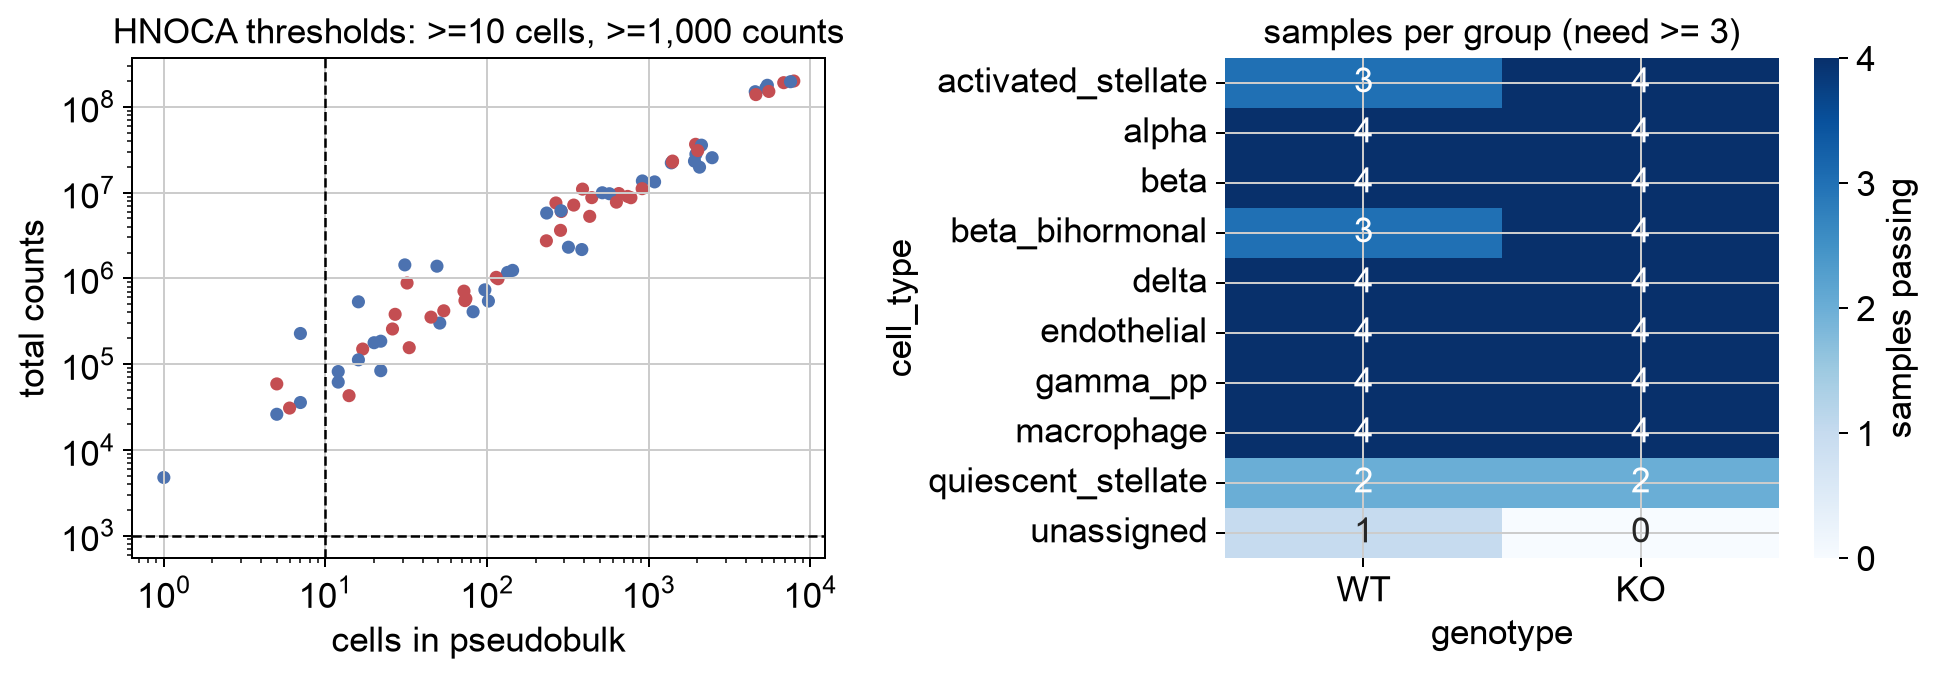

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(pdata.obs[NCELLS], pdata.obs["psbulk_counts"], s=18,
                c=["#C44E52" if g == "KO" else "#4C72B0" for g in pdata.obs["genotype"]])
axes[0].axvline(cfg.MIN_CELLS_PER_PSEUDOBULK, ls="--", c="k", lw=1)
axes[0].axhline(cfg.MIN_COUNTS_PER_PSEUDOBULK, ls="--", c="k", lw=1)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("cells in pseudobulk"); axes[0].set_ylabel("total counts")
axes[0].set_title("HNOCA thresholds: >=10 cells, >=1,000 counts")

keep = ((pdata.obs[NCELLS] >= cfg.MIN_CELLS_PER_PSEUDOBULK)
        & (pdata.obs["psbulk_counts"] >= cfg.MIN_COUNTS_PER_PSEUDOBULK))
surviving = (pdata.obs[keep].groupby([CELLTYPE_KEY, "genotype"], observed=True)
             .size().unstack(fill_value=0))
sns.heatmap(surviving, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            cbar_kws={"label": "samples passing"})
axes[1].set_title(f"samples per group (need >= {cfg.MIN_SAMPLES_PER_GROUP})")
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "05_pseudobulk_qc.png", dpi=300, bbox_inches="tight")

pdata = pdata[keep].copy()
testable = surviving[(surviving >= cfg.MIN_SAMPLES_PER_GROUP).all(axis=1)].index.tolist()
print(f"\ntestable cell types: {testable}")
print(f"skipped (too few samples): "
      f"{[c for c in surviving.index if c not in testable]}")

QC looks healthy. 8 testable cell types: activated_stellate, alpha, beta, beta_bihormonal, delta, endothelial, gamma_pp, macrophage — with quiescent_stellate and unassigned correctly skipped (too few samples). The scatter shows almost all profiles clearing the ≥10 cells / ≥1,000 counts thresholds; the few below are the rare-type profiles that get dropped, as intended.

The important ones for your story all pass at full strength:

beta: 4 WT / 4 KO — your primary, full power.
alpha: 4 / 4 — your systemic/never-recombined control (this is what lets us test cell-autonomy: a gene that moves in beta but not alpha is cell-autonomous).
delta: 4 / 4 — the secondary target (recombined via Pdx1).
beta_bihormonal: 3 WT / 4 KO — testable, but note it's borderline on the WT side (the WT bihormonal cells are the rare ~0.4% population). KO-vs-WT within bihormonal is a slightly odd contrast since bihormonal is KO-enriched — useful but not the headline; don't over-read it.

### Genes to exclude

Drop genes expressed in fewer than 1% of cells, and drop sex
chromosome genes. The second matters if your cohort is mixed-sex — otherwise
`Xist` and the Y genes will be your top hits and they have nothing to do with
Bola3.

Mitochondrially-encoded genes are also excluded from testing. In a
mitochondrial-disease model this feels counterintuitive, but the mito fraction
is dominated by per-cell technical variation and by whatever you decided at the
QC step in notebook 01; the informative signal is in the ~1,100 *nuclear*
genes encoding mitochondrial proteins, which are retained. Their behaviour
is exactly what notebook 06 scores.

In [5]:
sc.pp.calculate_qc_metrics(adata, percent_top=None, log1p=False, inplace=True)
pct_cells = np.asarray((adata.layers["counts"] > 0).mean(axis=0)).ravel() * 100
low_expr = set(adata.var_names[pct_cells < 1.0])

SEX_GENES = {"Xist", "Tsix", "Ddx3y", "Eif2s3y", "Uty", "Kdm5d", "Erdr1"}
mito_genes = set(adata.var_names[adata.var_names.str.startswith(cfg.MOUSE_MITO_PREFIX)])

drop = low_expr | SEX_GENES | mito_genes
pdata = pdata[:, ~pdata.var_names.isin(drop)].copy()
print(f"excluded {len(low_expr)} low-expression, {len(SEX_GENES & set(adata.var_names))} "
      f"sex-linked, {len(mito_genes)} mito-encoded genes")
print(f"{pdata.n_vars} genes retained for testing")

excluded 9763 low-expression, 6 sex-linked, 13 mito-encoded genes
12899 genes retained for testing


### Does the pseudobulk separate by genotype?

A PCA of the pseudobulk profiles. If samples separate by `batch` more strongly
than by `genotype`, include `batch` in the design formula below — and if
batch and genotype are perfectly confounded, no design can rescue that, and
you need to say so.

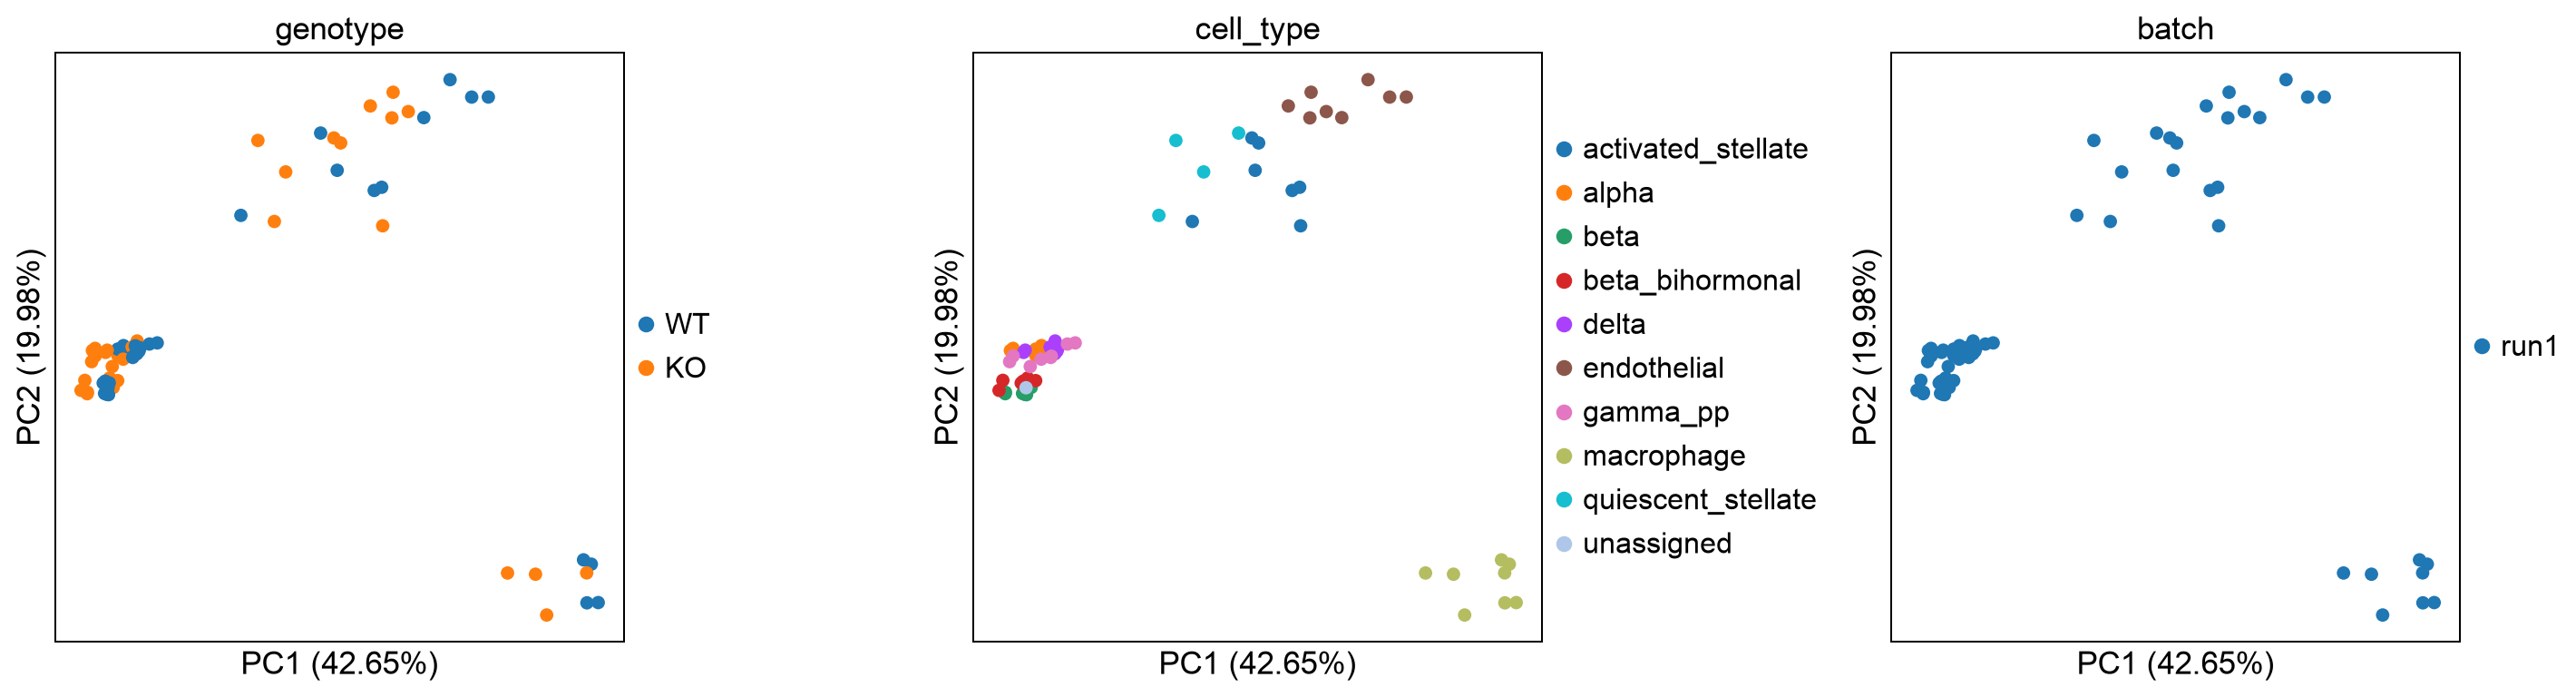

In [6]:
ppca = pdata.copy()
sc.pp.normalize_total(ppca, target_sum=1e6)
sc.pp.log1p(ppca)
sc.pp.pca(ppca, n_comps=min(8, ppca.n_obs - 1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, colour in zip(axes, ["genotype", CELLTYPE_KEY, "batch"]):
    sc.pl.pca(ppca, color=colour, ax=ax, show=False, size=140, frameon=True,
              annotate_var_explained=True, title=colour)
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "05_pseudobulk_pca.png", dpi=300, bbox_inches="tight")

Gene exclusions: 12,899 genes retained (dropped 9,763 low-expression, 6 sex-linked, 13 mito-encoded). That's a touch lower than typical because the <1% filter is stringent on islet data, but 12,899 is plenty for pseudobulk DE — no concern.

PCA —--

cell_type panel: PC1 (42.7%) cleanly separates cell types — the endocrine cells (beta/alpha/delta/gamma_pp/bihormonal) cluster together bottom-left, with stellate/endothelial/macrophage as the outliers. Cell type is the dominant axis, as it should be.
genotype panel: WT and KO are intermixed within each cluster — no dramatic global split. This is the right outcome: if WT/KO separated hard on PC1, that would signal a batch or quality confound. They don't, so the genotype effect is subtle, real, and lives within each cell type — exactly what DESeq2-per-cell-type is built to test.
batch panel: single color (all run1). No batch structure → the design stays ~genotype, nothing to correct.

So the pseudobulk is clean and the design is uncomplicated

### 5.2 Differential expression per cell type

One DESeq2 fit per cell type. `~ genotype`, or `~ batch + genotype` when your
samples span multiple processing days — the batch term absorbs day-to-day
variation so it is not attributed to the knockout.

In [7]:
USE_BATCH = pdata.obs["batch"].nunique() > 1
DESIGN = "~batch + genotype" if USE_BATCH else "~genotype"
print(f"design: {DESIGN}")

results = {}
for ct in testable:
    sub = pdata[pdata.obs[CELLTYPE_KEY] == ct].copy()

    # HNOCA/edgeR-style expression filter, applied within each cell type
    genes = dc.pp.filter_by_expr(sub, group="genotype", min_count=10,
                                 min_total_count=15, inplace=False)
    sub = sub[:, genes].copy()

    if USE_BATCH and sub.obs.groupby(["batch", "genotype"], observed=True).size().min() == 0:
        design = "~genotype"
        print(f"  {ct}: batch not estimable here, falling back to ~genotype")
    else:
        design = DESIGN

    dds = DeseqDataSet(adata=sub, design=design, refit_cooks=True, quiet=True)
    dds.deseq2()
    stats = DeseqStats(dds, contrast=["genotype", "KO", "WT"], quiet=True)
    stats.summary()

    res = stats.results_df.copy()
    res["cell_type"] = ct
    res["gene"] = res.index
    res["n_cells_KO"] = sub.obs.loc[sub.obs.genotype == "KO", NCELLS].sum()
    res["n_cells_WT"] = sub.obs.loc[sub.obs.genotype == "WT", NCELLS].sum()
    results[ct] = res

    n_sig = (res.padj < cfg.FDR_ALPHA).sum()
    n_up = ((res.padj < cfg.FDR_ALPHA) & (res.log2FoldChange > 0)).sum()
    print(f"  {ct:22s} {sub.n_vars:5d} genes tested | {n_sig:4d} at FDR<{cfg.FDR_ALPHA} "
          f"({n_up} up, {n_sig - n_up} down in KO)")

de = pd.concat(results.values(), ignore_index=True)
de.to_csv(cfg.TABLE_DIR / "05_pseudobulk_de_all.csv", index=False)
de[de.padj < cfg.FDR_ALPHA].sort_values(["cell_type", "padj"]).to_csv(
    cfg.TABLE_DIR / "05_pseudobulk_de_significant.csv", index=False)

design: ~genotype


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/pydeseq2/dds.py:822: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)


  activated_stellate      1923 genes tested |    1 at FDR<0.05 (0 up, 1 down in KO)
  alpha                  12295 genes tested | 3779 at FDR<0.05 (2022 up, 1757 down in KO)
  beta                   12584 genes tested | 4877 at FDR<0.05 (2566 up, 2311 down in KO)
  beta_bihormonal         7498 genes tested |   57 at FDR<0.05 (31 up, 26 down in KO)
  delta                  12286 genes tested | 3577 at FDR<0.05 (1950 up, 1627 down in KO)
  endothelial             4992 genes tested |  710 at FDR<0.05 (326 up, 384 down in KO)
  gamma_pp               11282 genes tested | 2517 at FDR<0.05 (1628 up, 889 down in KO)
  macrophage              6755 genes tested | 1546 at FDR<0.05 (679 up, 867 down in KO)


### Sanity check: is Bola3 itself down in the KO?

The strongest available positive control. If Bola3 does not come out
significantly reduced in the KO pseudobulk, something is wrong upstream —
sample labels swapped, wrong reference annotation, or a knockout strategy that
leaves the transcript intact. Check this before reading any other result.

In [9]:
b3 = de[de.gene == "Bola3"].set_index("cell_type")[
    ["baseMean", "log2FoldChange", "pvalue", "padj"]]
display(b3.round(4))
if len(b3) and (b3["log2FoldChange"] < 0).all():
    print("Bola3 is reduced in KO across all tested cell types — as expected.")
else:
    print("WARNING: Bola3 is not consistently reduced in all cell types. Verify beta cell specific reduction as Pdx1CreEr used.")

,baseMean,log2FoldChange,pvalue,padj
cell_type,,,,
activated_stellate,12.2364,0.3552,0.4716,0.9901
alpha,2393.6452,-0.1047,0.1664,0.2952
beta,9608.4505,-0.4472,0.0002,0.0012
beta_bihormonal,160.7246,0.0951,0.6704,0.9377
delta,1058.3597,-0.3034,0.0013,0.0081
endothelial,19.1607,1.0596,0.0177,0.0946
gamma_pp,405.7164,-0.2425,0.1886,0.3493
macrophage,42.1687,0.5822,0.1716,0.3355


This is not  a global knockout. Its a is Pdx1-CreER — beta-restricted, so Bola3 should drop only where Cre fired, and stay flat everywhere else. The .all() sees the (noisy, non-significant) positive values in macrophage/endothelial/stellate and trips the warning.

The positive control actually passed — beautifully. Read the table by significance:

beta: log2FC −0.45, padj 0.0012 ✓ significantly down
delta: log2FC −0.30, padj 0.0081 ✓ significantly down
alpha, gamma_pp, macrophage, endothelial, stellate, bihormonal: not significant (padj 0.09–0.99). The positive log2FCs there (endothelial +1.06, macrophage +0.58) are just noise on tiny baseMean (19 and 42 — Bola3 is barely expressed in those cells, so the fold-change is unstable and meaningless).

So Bola3 falls exactly where Pdx1-CreER recombines (beta and delta) and nowhere else. That's not just a passing control — it's better than "down everywhere," because it's a cell-type-specificity control that independently confirms your Cre driver is beta/delta-restricted. Exactly the biology you designed.

On magnitude: −0.45 log2FC in beta = ~27% reduction at the pseudobulk level — that's the diluted whole-beta drop we predicted (recombination ~38% × ~50% residual), and it's still significant. The true cell-autonomous drop in recombined cells is steeper; this is the lower bound, as expected.

Two things worth noting from the summary---

Alpha has 3,779 significant genes — and alpha never recombined. That's your systemic effect, and it's large. It means the beta 4,877 is a mix of cell-autonomous + systemic. This is precisely why the cell-autonomy contrasts (#2 moved-vs-WT, #3 moved-vs-non-moved) matter — and why comparing beta's DE to alpha's is informative. 5.5 (the Jaccard overlap) will quantify how much is shared/systemic.
The dispersion warning ("mean-based dispersion trend") is the benign PyDESeq2 small-n fallback (same as in Milo) — results are valid, FDR is just slightly approximate.

### 5.3 Volcano plots

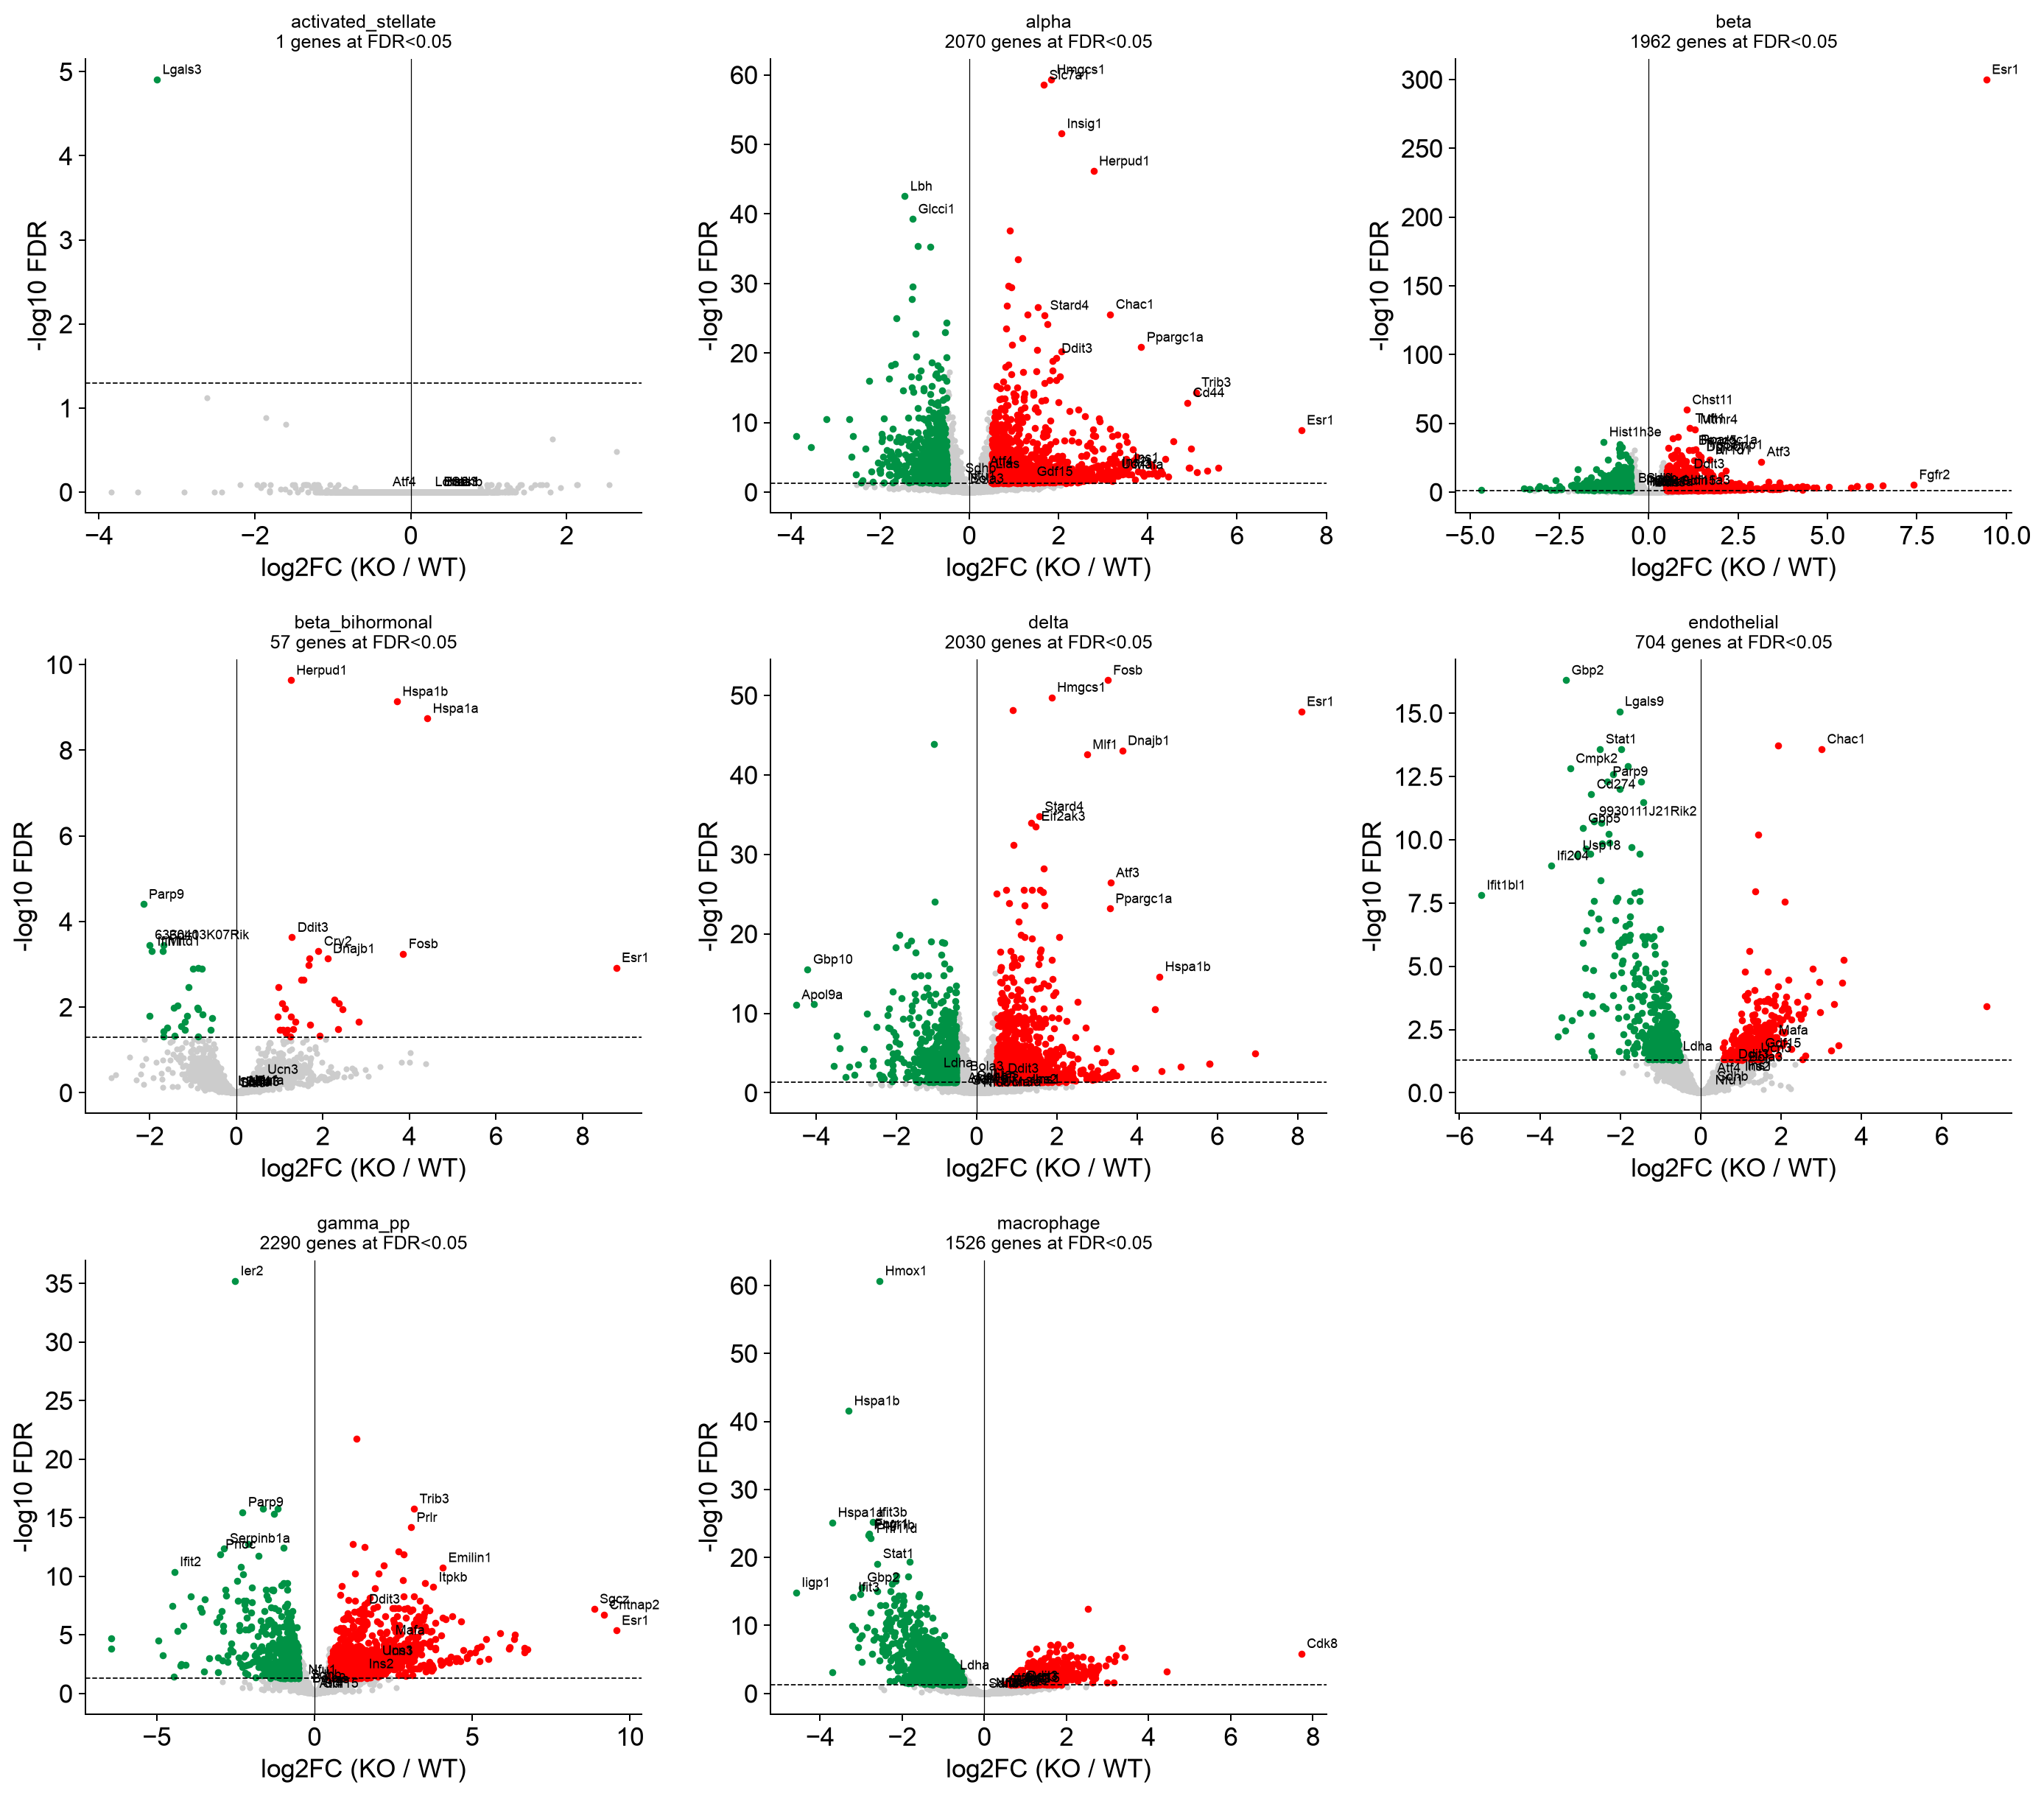

In [13]:
def volcano(res, ax, title, n_label=12, highlight=None):
    d = res.dropna(subset=["padj"]).copy()
    d["nlog10p"] = -np.log10(d["padj"].clip(lower=1e-300))
    sig = (d.padj < cfg.FDR_ALPHA) & (d.log2FoldChange.abs() > cfg.LFC_THRESHOLD)

    ax.scatter(d.loc[~sig, "log2FoldChange"], d.loc[~sig, "nlog10p"],
               s=5, c="#cccccc", rasterized=True)
    ax.scatter(d.loc[sig & (d.log2FoldChange > 0), "log2FoldChange"],
               d.loc[sig & (d.log2FoldChange > 0), "nlog10p"], s=8, c="#ff0000")
    ax.scatter(d.loc[sig & (d.log2FoldChange < 0), "log2FoldChange"],
               d.loc[sig & (d.log2FoldChange < 0), "nlog10p"], s=8, c="#009245")

    to_label = d[sig].reindex(
        d[sig].assign(rank=lambda x: x.nlog10p * x.log2FoldChange.abs())
        .sort_values("rank", ascending=False).index)[:n_label]
    if highlight:
        extra = d[d.gene.isin(highlight) & d.index.isin(d.index)]
        to_label = pd.concat([to_label, extra]).drop_duplicates("gene")
    for _, r in to_label.iterrows():
        ax.annotate(r["gene"], (r.log2FoldChange, r.nlog10p), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")

    ax.axhline(-np.log10(cfg.FDR_ALPHA), ls="--", c="k", lw=0.7)
    ax.axvline(0, ls="-", c="k", lw=0.5)
    ax.set_xlabel("log2FC (KO / WT)"); ax.set_ylabel("-log10 FDR")
    ax.set_title(f"{title}\n{sig.sum()} genes at FDR<{cfg.FDR_ALPHA}", fontsize=10)
    ax.grid(False)
    sns.despine(ax=ax)


key_genes = ["Bola3", "Nfu1", "Lias", "Sdhb", "Atf4", "Ddit3", "Fgf21", "Gdf15",
             "Aldh1a3", "Ucn3", "Mafa", "Ins1", "Ins2", "Ldha", "Slc16a1"]

n = len(testable)
ncol = 3
fig, axes = plt.subplots((n + ncol - 1) // ncol, ncol,
                         figsize=(5.2 * ncol, 4.6 * ((n + ncol - 1) // ncol)))
for ax, ct in zip(np.atleast_1d(axes).flat, testable):
    volcano(results[ct], ax, ct, highlight=key_genes)
for ax in np.atleast_1d(axes).flat[n:]:
    ax.axis("off")
fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "05_volcanoes.png", dpi=300, bbox_inches="tight")

### 5.4 Which cell type responds most?

The expectation, given that beta cells depend on mitochondrial ATP production
to secrete insulin, is that beta cells carry the largest response.

,n_tested,n_sig,n_up,n_down,median_abs_lfc,pct_sig,cells_KO,cells_WT
cell_type,,,,,,,,
beta,12584,4877,2566,2311,0.229559,38.76,24933.0,22863.0
alpha,12295,3779,2022,1757,0.253528,30.74,6776.0,7391.0
delta,12286,3577,1950,1627,0.245965,29.11,3085.0,6542.0
gamma_pp,11282,2517,1628,889,0.341684,22.31,1853.0,1610.0
macrophage,6755,1546,679,867,0.514736,22.89,705.0,983.0
endothelial,4992,710,326,384,0.367354,14.22,290.0,332.0
beta_bihormonal,7498,57,31,26,0.248918,0.76,977.0,96.0
activated_stellate,1923,1,0,1,0.324638,0.05,145.0,54.0


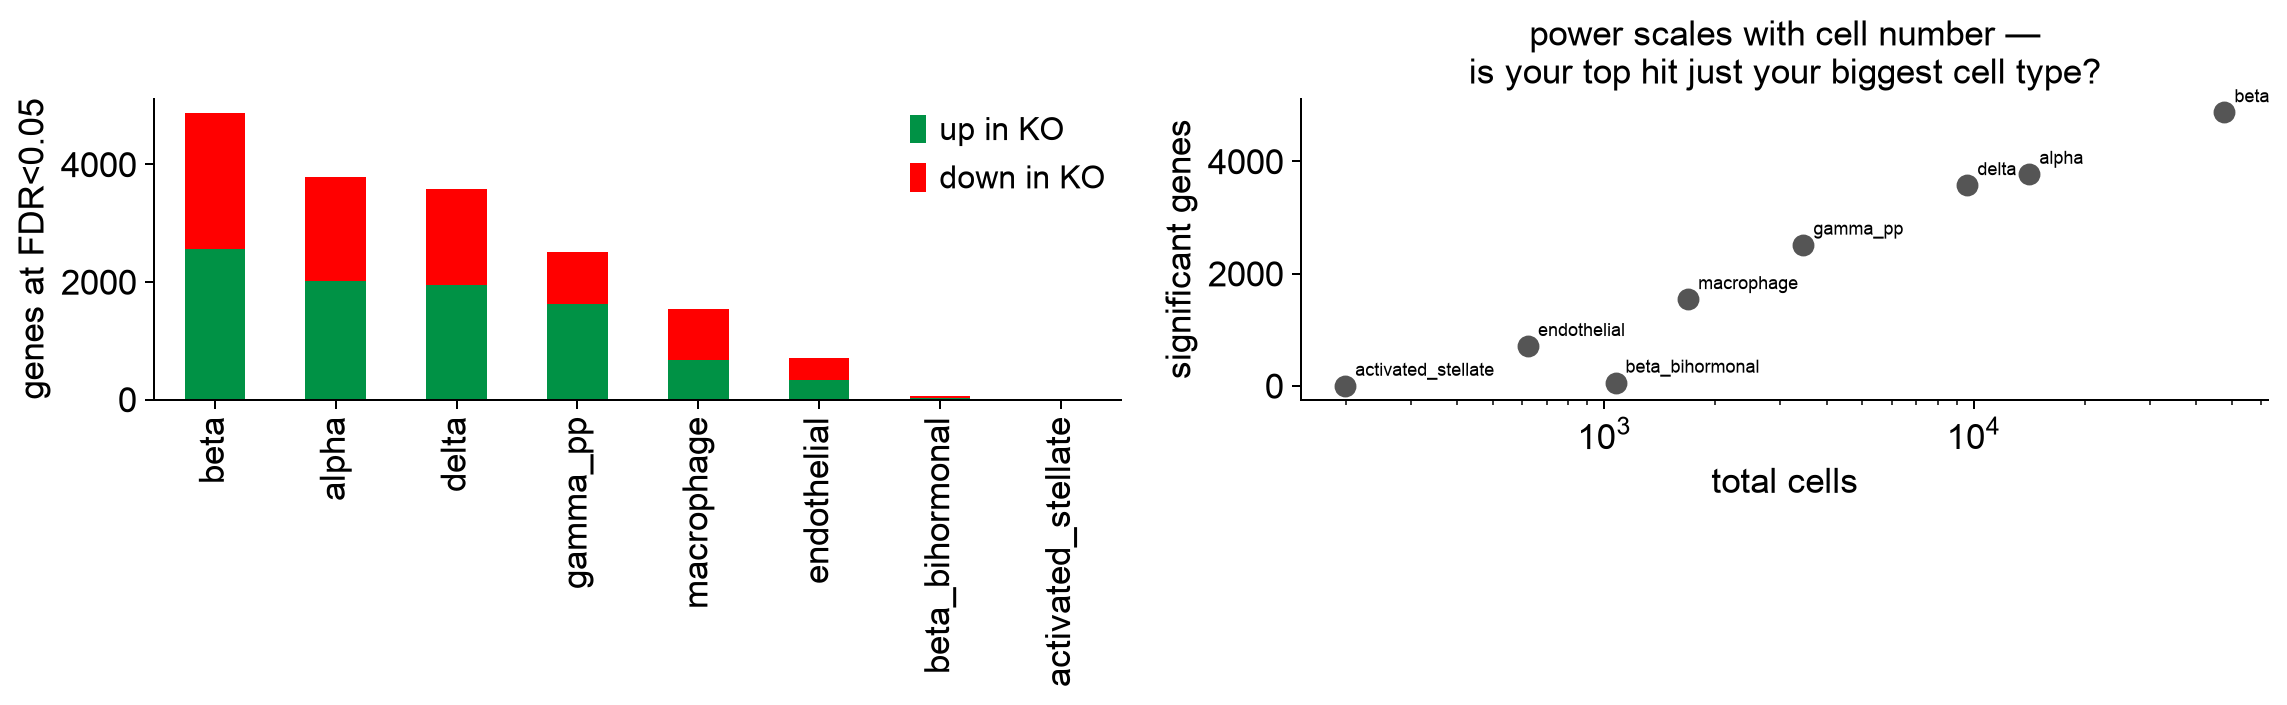

In [20]:
de["is_sig"] = de["padj"] < cfg.FDR_ALPHA
de["sig_up"] = de["is_sig"] & (de["log2FoldChange"] > 0)
de["sig_down"] = de["is_sig"] & (de["log2FoldChange"] < 0)

burden = de.groupby("cell_type").agg(
    n_tested=("gene", "size"),
    n_sig=("is_sig", "sum"),
    n_up=("sig_up", "sum"),
    n_down=("sig_down", "sum"),
    median_abs_lfc=("log2FoldChange", lambda x: x.abs().median()),
)
burden["pct_sig"] = (100 * burden.n_sig / burden.n_tested).round(2)
burden["cells_KO"] = de.groupby("cell_type")["n_cells_KO"].first()
burden["cells_WT"] = de.groupby("cell_type")["n_cells_WT"].first()
display(burden.sort_values("n_sig", ascending=False))
burden.to_csv(cfg.TABLE_DIR / "05_de_burden_by_celltype.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
b = burden.sort_values("n_sig", ascending=False)
b[["n_up", "n_down"]].plot(kind="bar", stacked=True, ax=axes[0],
                           color=["#009245", "#ff0000"], grid=False)
axes[0].set_ylabel(f"genes at FDR<{cfg.FDR_ALPHA}"); axes[0].set_xlabel("")
axes[0].legend(["up in KO", "down in KO"], frameon=False)


axes[1].scatter(b.cells_KO + b.cells_WT, b.n_sig, s=60, c="#555")
for ct, r in b.iterrows():
    axes[1].annotate(ct, (r.cells_KO + r.cells_WT, r.n_sig), fontsize=7,
                     xytext=(4, 4), textcoords="offset points")
    axes[1].grid(False)
axes[1].set_xscale("log")
axes[1].set_xlabel("total cells"); axes[1].set_ylabel("significant genes")
axes[1].set_title("power scales with cell number —\nis your top hit just your biggest cell type?")
sns.despine(fig); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "05_de_burden.png", dpi=300, bbox_inches="tight")

The right-hand panel is a check, not a result. Cell types with more cells give
more stable pseudobulk estimates and therefore more significant genes. Beta
cells topping the list is only meaningful if they top it by more than their
cell-number advantage predicts.

5.4 burden — beta is the most affected, and not just because it's biggest. Beta has 4,877 significant genes at the highest pct_sig = 38.8%, above alpha (30.7%) and delta (29.1%). Since pct_sig normalizes for how many genes were tested, beta tops the list by more than its cell-number advantage predicts — exactly what to expect for a cell type that lives or dies by mitochondrial ATP. That's a clean, defensible headline: beta cells mount the largest transcriptional response.

### 5.5 Shared versus cell-type-specific responses

,gene,n_cell_types,mean_lfc
0,Chmp4b,7,-0.930968
1,Parp9,7,-2.055755
2,Srf,7,1.420894
3,Eif2ak2,7,-1.666221
4,Ifih1,7,-1.478757
5,Usp18,7,-2.045083
6,Herc6,7,-1.782523
7,Herpud1,7,1.523388
8,Stat1,7,-2.005704
9,Mitd1,7,-1.732826


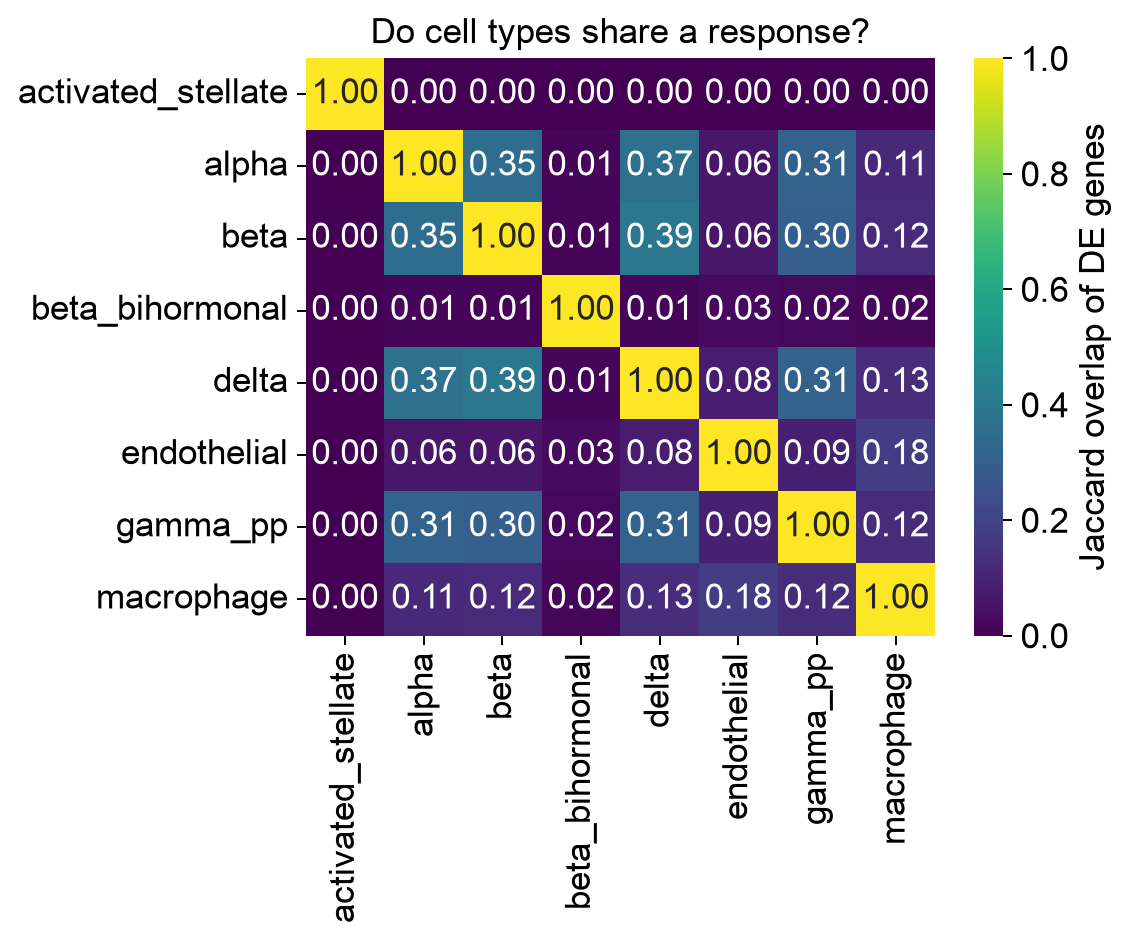

In [22]:
sig_sets = {ct: set(r.loc[r.padj < cfg.FDR_ALPHA, "gene"]) for ct, r in results.items()}
sig_sets = {k: v for k, v in sig_sets.items() if v}

if len(sig_sets) > 1:
    types = list(sig_sets)
    jac = pd.DataFrame(index=types, columns=types, dtype=float)
    for a in types:
        for b_ in types:
            u = len(sig_sets[a] | sig_sets[b_])
            jac.loc[a, b_] = len(sig_sets[a] & sig_sets[b_]) / u if u else np.nan
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    sns.heatmap(jac.astype(float), annot=True, fmt=".2f", cmap="viridis", ax=ax,
                cbar_kws={"label": "Jaccard overlap of DE genes"})
    ax.set_title("Do cell types share a response?")
    ax.grid(False)
    fig.tight_layout()
    fig.savefig(cfg.FIG_DIR / "05_de_overlap.png", dpi=300, bbox_inches="tight")

    from collections import Counter

    freq = Counter(g for s in sig_sets.values() for g in s)
    core = pd.DataFrame(freq.most_common(30), columns=["gene", "n_cell_types"])
    core["mean_lfc"] = core.gene.map(
        de[de.padj < cfg.FDR_ALPHA].groupby("gene")["log2FoldChange"].mean())
    display(core)
    core.to_csv(cfg.TABLE_DIR / "05_core_response_genes.csv", index=False)

A gene changing in every cell type points to a cell-autonomous consequence of
losing Bola3 everywhere — expected if your knockout is global rather than
beta-cell specific. A response confined to beta cells points either to a
beta-specific driver or to beta cells being uniquely vulnerable to the lesion.
Which of those you have depends on your mouse model, and it changes the story.

5.5 shows overlap — but a big chunk is systemic. Beta shares ~35–39% of its DE genes with alpha, delta, and gamma_pp (Jaccard 0.35/0.39/0.30). Alpha never recombined, so those shared genes are a systemic program, not cell-autonomous Bola3 loss. And you can see what it is in the volcanoes — Chac1, Ddit3, Trib3, Atf3, Ppargc1a, Hspa1a/b, Herpud1 (the ISR/UPR stress axis) are up across beta, alpha, and delta. So roughly a third of beta's DE is the animals' systemic metabolic stress; the beta-specific two-thirds is where the cell-autonomous signal lives.
Esr1 is a massive outlier (log2FC ~10, top hit in beta/alpha/delta/bihormonal). A change that large and that uniform across cell types is either a strong systemic induction or partly artifactual — note it, but don't hang the story on it.

### 5.6 Heatmap of the top beta cell hits

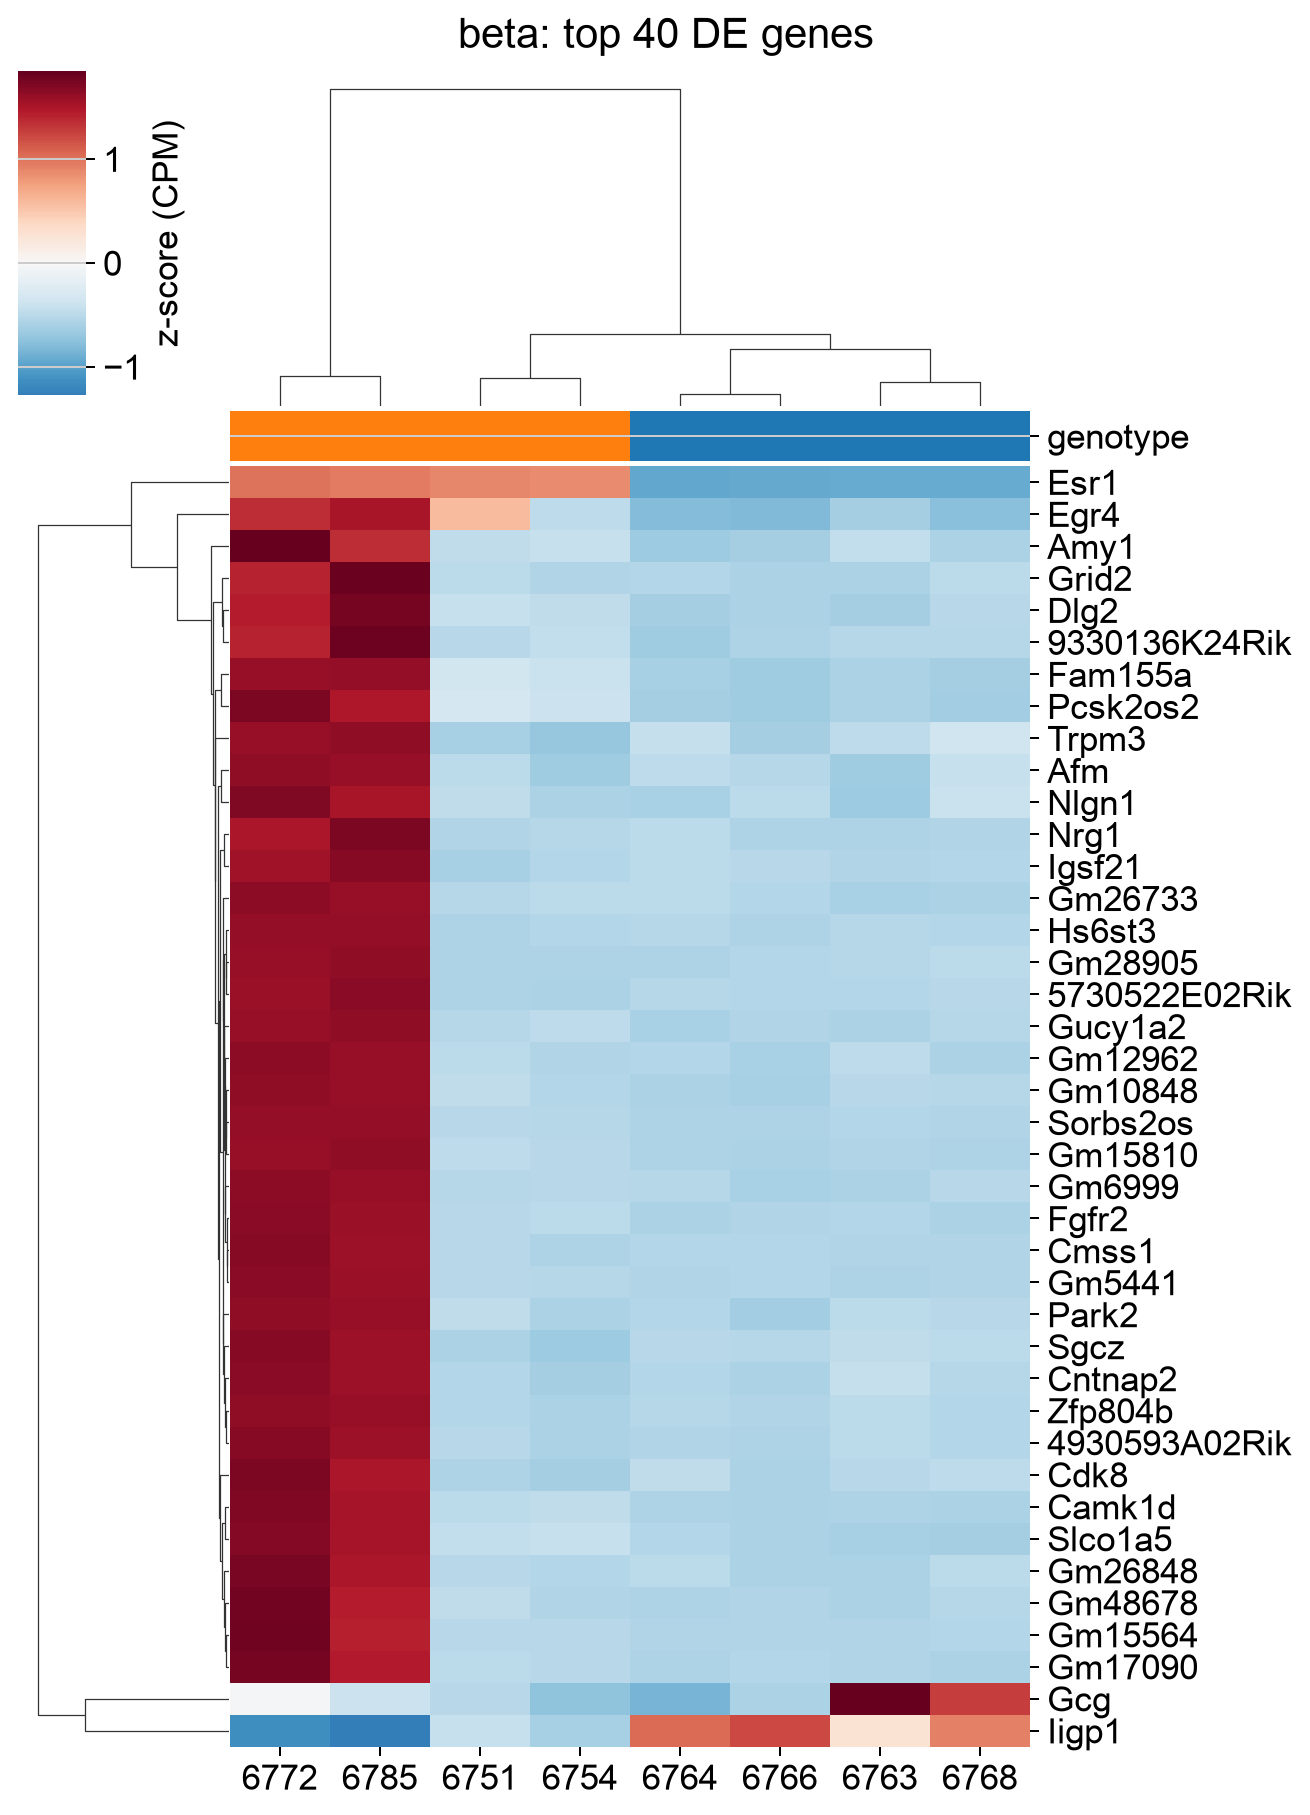

In [25]:
FOCUS = "beta" if "beta" in results else testable[0] 
res = results[FOCUS] 
top = (res[res.padj < cfg.FDR_ALPHA] .reindex(res[res.padj < cfg.FDR_ALPHA].log2FoldChange.abs() .sort_values(ascending=False).index)[:40]) 

if len(top): 
    sub = pdata[pdata.obs[CELLTYPE_KEY] == FOCUS].copy() 
    sc.pp.normalize_total(sub, target_sum=1e6); sc.pp.log1p(sub) 
    mat = pd.DataFrame( np.asarray(sub[:, top.gene].X), index=sub.obs["sample_id"].values, columns=top.gene.values, ) 
    z = (mat - mat.mean()) / mat.std() 
    
    # Define your custom genotype color mapping here (e.g., WT vs KO)
    GENOTYPE_COLORS = {
        "WT": "#1f77b4",   # Blue
        "KO": "#ff7f0e",   # Orange
    }
    
    # Map using your explicit dictionary instead of the global PALETTE
    col_colors = pd.Series(
        [GENOTYPE_COLORS.get(g, "#cccccc") for g in sub.obs["genotype"]], 
        index=mat.index, 
        name="genotype"
    )
    
    g = sns.clustermap(z.T, cmap="RdBu_r", center=0, figsize=(7.5, 10), col_colors=col_colors, yticklabels=True, cbar_kws={"label": "z-score (CPM)"}) 
    
    # Explicitly turn off the gridlines on the central heatmap matrix axis
    g.ax_heatmap.grid(False)
    
    g.fig.suptitle(f"{FOCUS}: top 40 DE genes", y=1.01) 
    g.savefig(cfg.FIG_DIR / f"05_heatmap_{FOCUS}.png", dpi=300, bbox_inches="tight")


The 5.6 heatmap top-40 genes are driven by 6772 and 6785 — look at the intensity: the "up in KO" block is darkest in those two samples (leftmost), fading in 6751/6754. But 6772/6785 are your low-recombination, technically-overcalled samples. If these were the cell-autonomous Bola3 signature, they'd be strongest in the high-recombination animals (6751/6754), not the low ones. They're not. Combined with the gene list being heavy on neuronal/exocrine genes (Grid2, Nrg1, Cntnap2, Nlgn1, Amy1), the top-|LFC| hits look like they're driven by the two odd samples — either ambient contamination or a dedifferentiation signal, but not clean dose-dependent Bola3 loss. Don't cherry-pick the top-|LFC| genes as the signature. The robust cell-autonomous genes are the ones consistent across all four KO animals — which the pathway analysis (06) surfaces via aggregation, and which #3 isolates directly.

The good news underneath the caveats: the genotype does cleanly separate on the heatmap (all KO red, all WT blue), Bola3 passed as the beta/delta-specific control, and beta is the most-affected type. The naive contrast is doing its job as a lower bound with a known systemic component.

### The beta-focused contrasts to separate cell-autonomous from systemic: #2 (moved-vs-WT) and #3 (moved-vs-non-moved)
Infact, #3 (moved vs non-moved within KO) is the one that cuts through both caveats at once — it's within-KO (removes the WT-vs-KO systemic axis) and phenotype-based (removes the Bola3-dropout and the 6772/6785 animal-level confound).

#2 (KO-moved vs WT beta) — the enriched signature: what the affected KO cells look like against normal WT beta. Less diluted than the naive contrast, closest to your in vitro. It's descriptive (you selected cells because they changed), so read it as "what the sick state expresses," not a hypothesis test.
#3 (moved vs non-moved within KO) — the cell-autonomous test, and the important one. It's within KO, so it removes the WT-vs-KO systemic axis, and paired by mouse_id where possible, which removes between-animal variance. 
Watch the printout: it tells you which animals have both groups. My worry is that after dropping the technical clusters, only the two high-KO animals (6751, 6754) have enough moved and non-moved cells → n=2 pairs, which is real but underpowered. If it says only 2 animals, we treat #3 as suggestive and lean on #2 + the pathway aggregation (06) for significance. If 3–4 animals qualify, #3 is your cleanest result.

#2  KO-moved vs WT beta
  profiles per group: {'WT': 4, 'KO_moved': 4}
  design: ~cond2
  3828 sig (2063 up, 1765 down) at FDR<0.05

#3  moved vs non-moved (within KO)
  profiles per group: {'nonmoved': 4, 'moved': 4}
  animals with both groups: ['KO_1', 'KO_2', 'KO_3', 'KO_4']
  design: ~mouse_id + status


/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/pydeseq2/dds.py:548: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()


  1142 sig (658 up, 484 down) at FDR<0.05



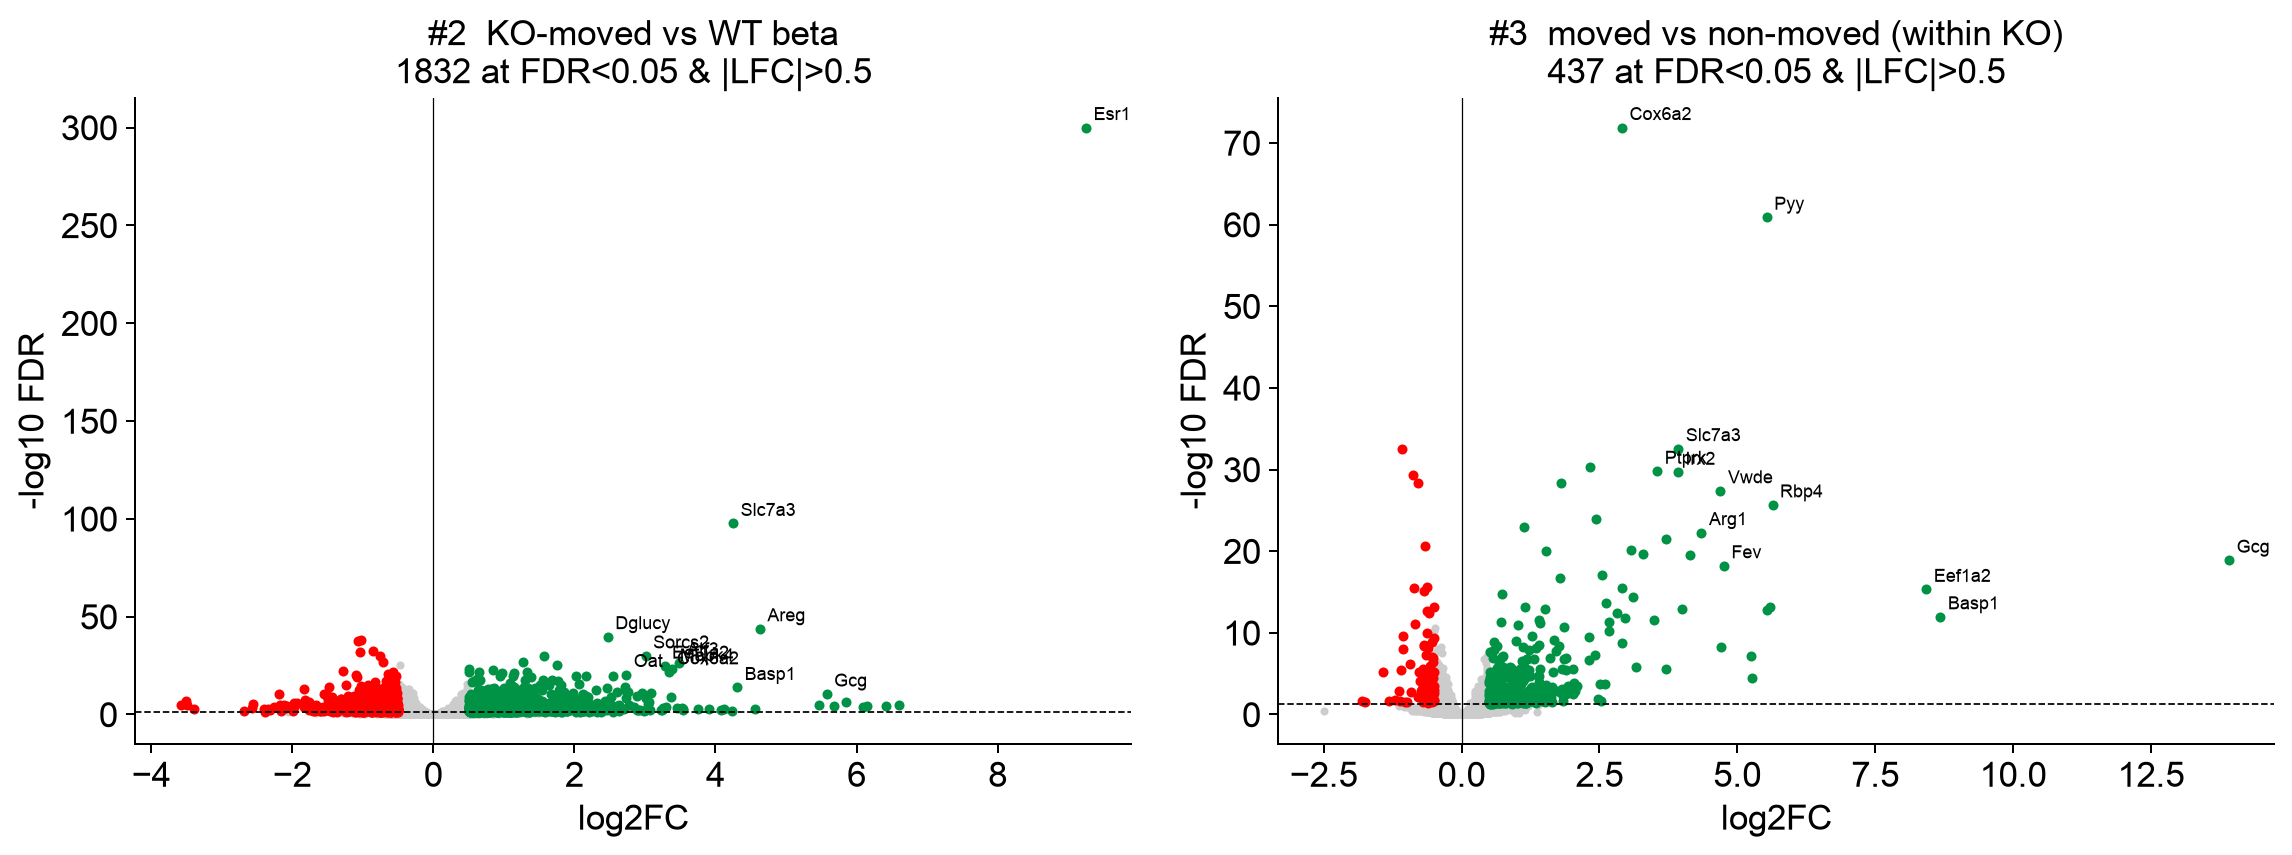

In [28]:
import decoupler as dc
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt, seaborn as sns
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

# ---- consistent palette ----
C_KO, C_WT, C_DOWN, C_UP = "#ff7f0e", "#1f77b4", "#ff0000", "#009245"

STATE_LABELS = {"0":"Mature β","1":"Mature β","4":"Mature β","5":"Mature β",
    "6":"Immature β","2":"Dedifferentiated β","9":"Dedifferentiated β",
    "3":"Transitional β","7":"Transitional β","na":"Bihormonal β"}
MOVED    = {"Dedifferentiated β", "Bihormonal β"}
NONMOVED = {"Mature β"}                      # clean healthy reference (broaden if you want more power)

adata.X = adata.layers["counts"].copy()      # DESeq2 needs raw integers
beta = adata[adata.obs["cell_type"].isin(["beta","beta_bihormonal"])].copy()
beta = beta[~beta.obs["beta_cluster"].astype(str).isin(["8","10"])].copy()   # drop technical clusters
beta.obs["beta_state"] = beta.obs["beta_cluster"].astype(str).map(lambda c: STATE_LABELS.get(c, c))

sc.pp.calculate_qc_metrics(beta, percent_top=None, log1p=False, inplace=True)
pct = np.asarray((beta.layers["counts"] > 0).mean(0)).ravel() * 100
DROP_GENES = (set(beta.var_names[pct < 1.0]) | {"Xist","Tsix","Ddx3y","Eif2s3y","Uty","Kdm5d","Erdr1"}
              | set(beta.var_names[beta.var_names.str.startswith("mt-")]))

def run_de(sub, cond_col, ref, alt, paired_by=None):
    sub = sub.copy()
    sub.obs["pb_sample"] = sub.obs["sample_id"].astype(str) + "__" + sub.obs[cond_col].astype(str)
    pb = dc.pp.pseudobulk(sub, sample_col="pb_sample", groups_col=None, mode="sum", layer="counts")
    meta = sub.obs.drop_duplicates("pb_sample").set_index("pb_sample")
    for c in [cond_col, "sample_id", "mouse_id", "genotype"]:
        pb.obs[c] = pb.obs.index.map(meta[c])
    ncol = "psbulk_cells" if "psbulk_cells" in pb.obs else "psbulk_n_cells"
    pb = pb[(pb.obs[ncol] >= 10) & (pb.obs["psbulk_counts"] >= 1000)].copy()
    pb = pb[:, ~pb.var_names.isin(DROP_GENES)].copy()
    pb.obs[cond_col] = pd.Categorical(pb.obs[cond_col], categories=[ref, alt], ordered=True)
    print("  profiles per group:", pb.obs.groupby(cond_col, observed=True).size().to_dict())

    design = f"~{cond_col}"
    if paired_by:
        both = pb.obs.groupby(paired_by, observed=True)[cond_col].nunique()
        keep = both[both == 2].index
        if len(keep) >= 2:
            pb = pb[pb.obs[paired_by].isin(keep)].copy()
            pb.obs[paired_by] = pb.obs[paired_by].astype("category")
            design = f"~{paired_by} + {cond_col}"
        print(f"  animals with both groups: {list(keep)}")
    print(f"  design: {design}")

    genes = dc.pp.filter_by_expr(pb, group=cond_col, min_count=10, min_total_count=15, inplace=False)
    pb = pb[:, genes].copy()
    dds = DeseqDataSet(adata=pb, design=design, refit_cooks=True, quiet=True); dds.deseq2()
    st = DeseqStats(dds, contrast=[cond_col, alt, ref], quiet=True); st.summary()
    res = st.results_df.copy(); res["gene"] = res.index
    ns = (res.padj < 0.05).sum(); nu = ((res.padj < 0.05) & (res.log2FoldChange > 0)).sum()
    print(f"  {ns} sig ({nu} up, {ns - nu} down) at FDR<0.05\n")
    return res

# ---- #2: KO "moved" (dedifferentiated+bihormonal) vs WT beta ----
c2 = pd.Series(index=beta.obs_names, dtype=object)
c2[beta.obs["genotype"] == "WT"] = "WT"
c2[(beta.obs["genotype"] == "KO") & beta.obs["beta_state"].isin(MOVED)] = "KO_moved"
sub2 = beta[c2.notna()].copy(); sub2.obs["cond2"] = c2.dropna().values
print("#2  KO-moved vs WT beta"); res2 = run_de(sub2, "cond2", ref="WT", alt="KO_moved")

# ---- #3: moved vs non-moved WITHIN KO (paired by animal) ----
ko = beta[beta.obs["genotype"] == "KO"].copy()
c3 = pd.Series(index=ko.obs_names, dtype=object)
c3[ko.obs["beta_state"].isin(MOVED)] = "moved"
c3[ko.obs["beta_state"].isin(NONMOVED)] = "nonmoved"
sub3 = ko[c3.notna()].copy(); sub3.obs["status"] = c3.dropna().values
print("#3  moved vs non-moved (within KO)"); res3 = run_de(sub3, "status", ref="nonmoved", alt="moved",
                                                           paired_by="mouse_id")

# ---- volcanoes (down=red, up=green) ----
def volcano(res, ax, title):
    d = res.dropna(subset=["padj"]).copy(); d["nlp"] = -np.log10(d["padj"].clip(lower=1e-300))
    sig = (d.padj < 0.05) & (d.log2FoldChange.abs() > 0.5)
    ax.scatter(d.loc[~sig,"log2FoldChange"], d.loc[~sig,"nlp"], s=5, c="#cccccc", rasterized=True)
    ax.scatter(d.loc[sig&(d.log2FoldChange>0),"log2FoldChange"], d.loc[sig&(d.log2FoldChange>0),"nlp"], s=9, c=C_UP)
    ax.scatter(d.loc[sig&(d.log2FoldChange<0),"log2FoldChange"], d.loc[sig&(d.log2FoldChange<0),"nlp"], s=9, c=C_DOWN)
    lab = d[sig].reindex(d[sig].assign(r=lambda x: x.nlp*x.log2FoldChange.abs())
                         .sort_values("r", ascending=False).index)[:12]
    for _, r in lab.iterrows():
        ax.annotate(r["gene"], (r.log2FoldChange, r.nlp), fontsize=7, xytext=(3,3), textcoords="offset points")
    ax.axhline(-np.log10(0.05), ls="--", c="k", lw=0.7); ax.axvline(0, c="k", lw=0.5)
    ax.set_xlabel("log2FC"); ax.set_ylabel("-log10 FDR")
    ax.set_title(f"{title}\n{sig.sum()} at FDR<0.05 & |LFC|>0.5"); sns.despine(ax=ax)
    ax.grid(False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
volcano(res2, axes[0], "#2  KO-moved vs WT beta")
volcano(res3, axes[1], "#3  moved vs non-moved (within KO)")
fig.tight_layout(); fig.savefig(cfg.FIG_DIR / "05_beta_moved_contrasts_volcano.png", dpi=300, bbox_inches="tight"); plt.show()

res2.to_csv(cfg.TABLE_DIR / "05_beta_moved_vs_WT.csv", index=False)
res3.to_csv(cfg.TABLE_DIR / "05_beta_moved_vs_nonmoved.csv", index=False)

#3 (moved vs non-moved within KO) — this is the cell-autonomous result, and it worked. All four KO animals had enough cells in both groups, so it ran the paired ~mouse_id + status design — the strongest possible, removing between-animal variance and the systemic axis at once. The most telling thing:

Esr1 — the massive outlier that dominated #2 and the naive contrast — is GONE from #3. That's not a loss, it's the proof the design works: Esr1 was a whole-KO (systemic) effect, so when you compare moved vs non-moved cells within the same animals, it cancels out. Everything left in #3 is genuinely cell-autonomous to the state transition.

And what's left is a coherent dedifferentiation program (up in moved): Pyy, Gcg (alt-islet hormones — loss of beta exclusivity), Rbp4, Fev (immature/progenitor markers), Arg1, Slc7a3 (arginine metabolism), Basp1. With mature-identity genes on the down (red) side. So the cell-autonomous consequence of Bola3 loss in a beta cell is dedifferentiation — measured with the systemic effect fully controlled. 1,142 genes, tighter and more interpretable than #2's 1,832.

#2 (KO-moved vs WT) is the broader enriched signature (Esr1, Slc7a3, Areg, Gcg up) — it includes the systemic component, so it's the "affected-state vs normal" descriptive view. Useful, but #3 is the one that isolates cause.

Three honest caveats:

The "residual df < 3" warning on #3 is expected — the paired n=4 design spends most of its degrees of freedom on the 4 animals, leaving little for dispersion estimation. So the exact FDR values are approximate; the direction and the top genes are reliable, the precise p-values less so. Inherent to n=4 paired — report it as such.
Partial circularity on the defining markers: the moved states were carved by clustering that partly captures dedifferentiation, so finding Gcg/Aldh1a3-type genes up is somewhat built-in. The value is the full coordinated program beyond the defining markers (Pyy, Fev, Arg1, Slc7a3, and the metabolic/ferroptosis genes that don't appear as top-|LFC| hits but move as a set).
Cox6a2 up is an odd single hit (it's a heart-type COX isoform) — possibly an aberrant isoform switch, possibly noise. Don't build on any single gene.

Where the metabolic/ferroptosis story is hiding: notice OXPHOS/Fe-S/lipoylation/ferroptosis genes are not in the top-|LFC| labels here — same as in 3c, they move as coordinated small shifts across many genes, not as headline hits. That's exactly what notebook 06 (pathway enrichment) surfaces by aggregation. So #3's result table is the perfect input for 06.

Two next steps:

Run 06 on #3's results (05_beta_moved_vs_nonmoved.csv) — this is where OXPHOS↓ / Fe-S↓ / ISR↑ / ferroptosis get their formal pathway test on the cell-autonomous contrast.
Cross-check #3 against your in vitro sc-beta KO — the genes shared between #3 and your in vitro DE are the validated cell-autonomous signature, and that overlap is a strong figure.

This is a genuinely good result — you now have a cell-autonomous dedifferentiation signature with the systemic effect provably removed

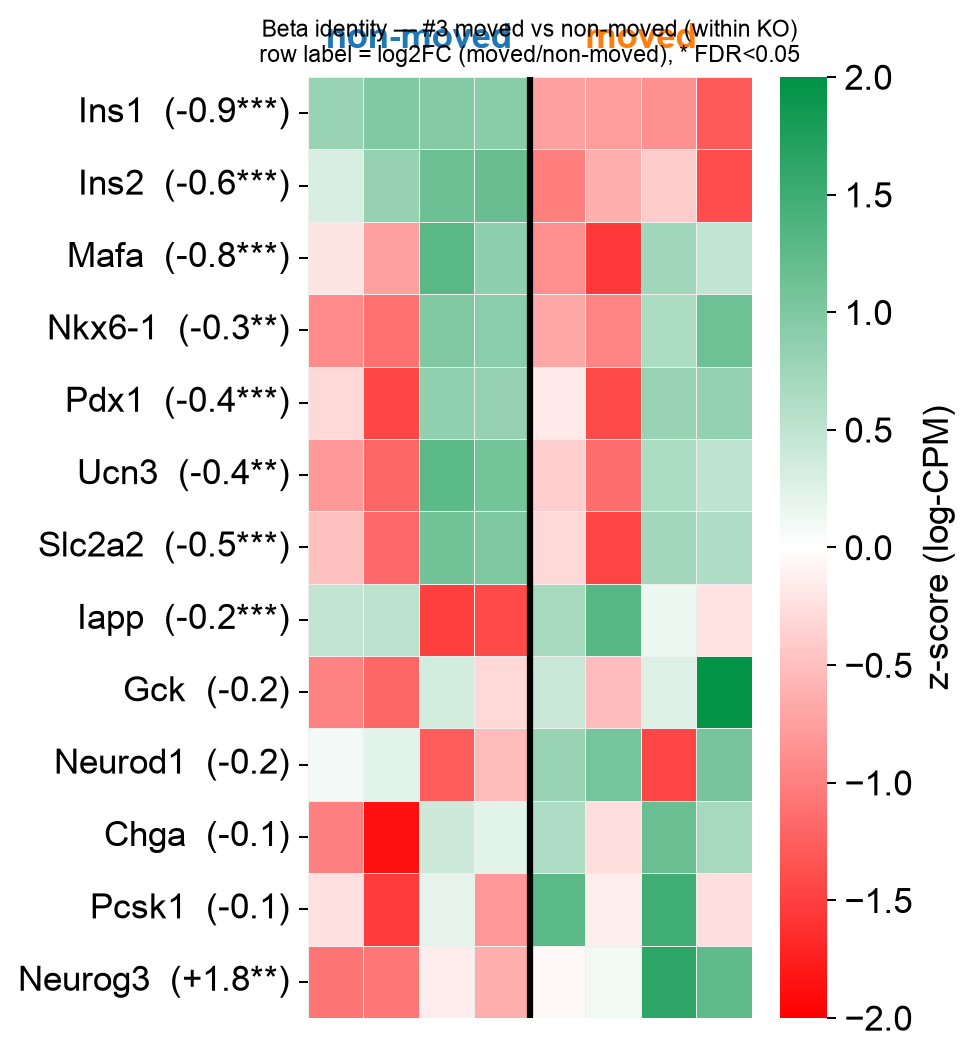

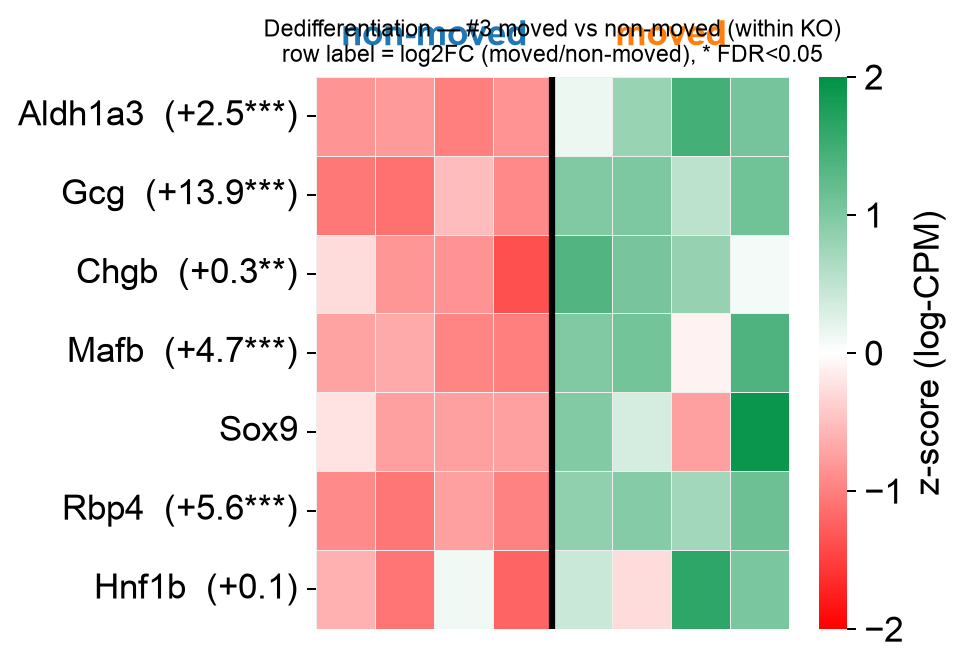

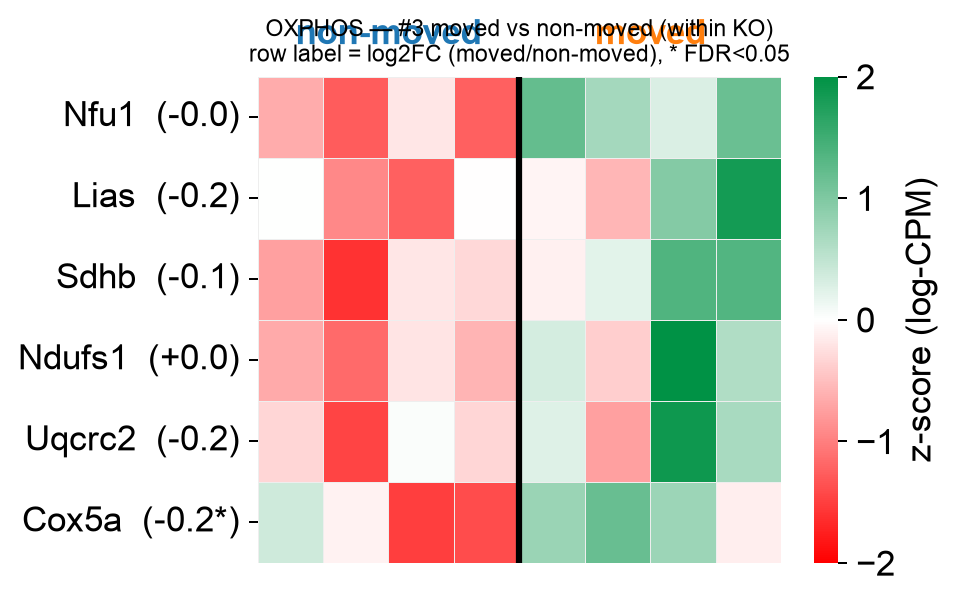

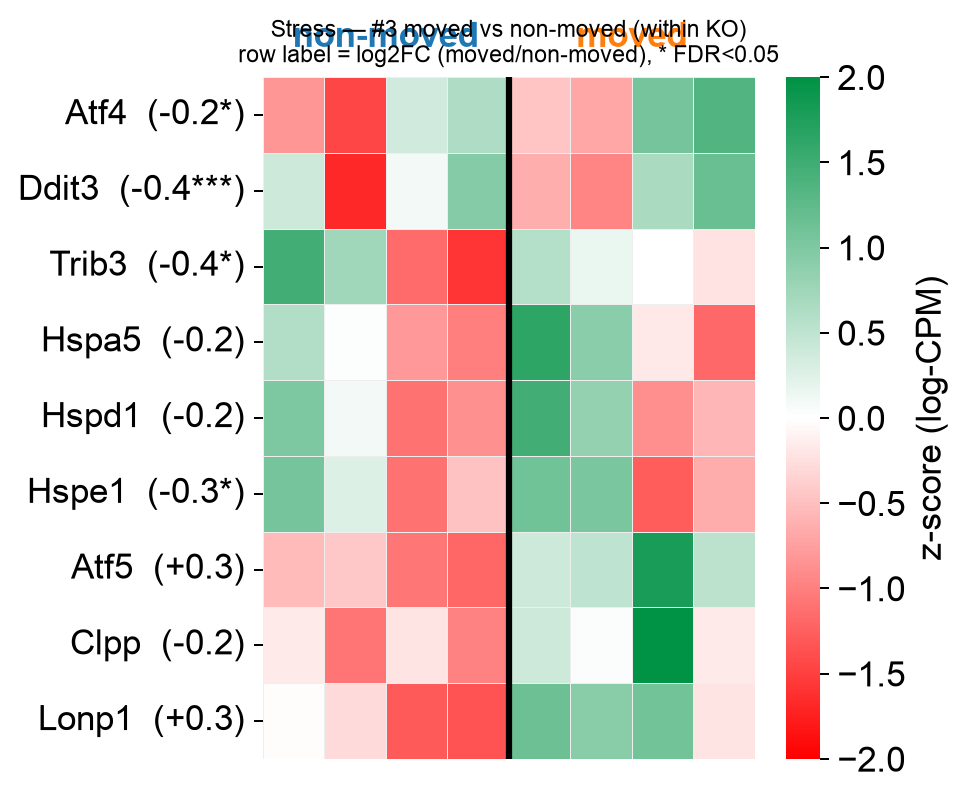

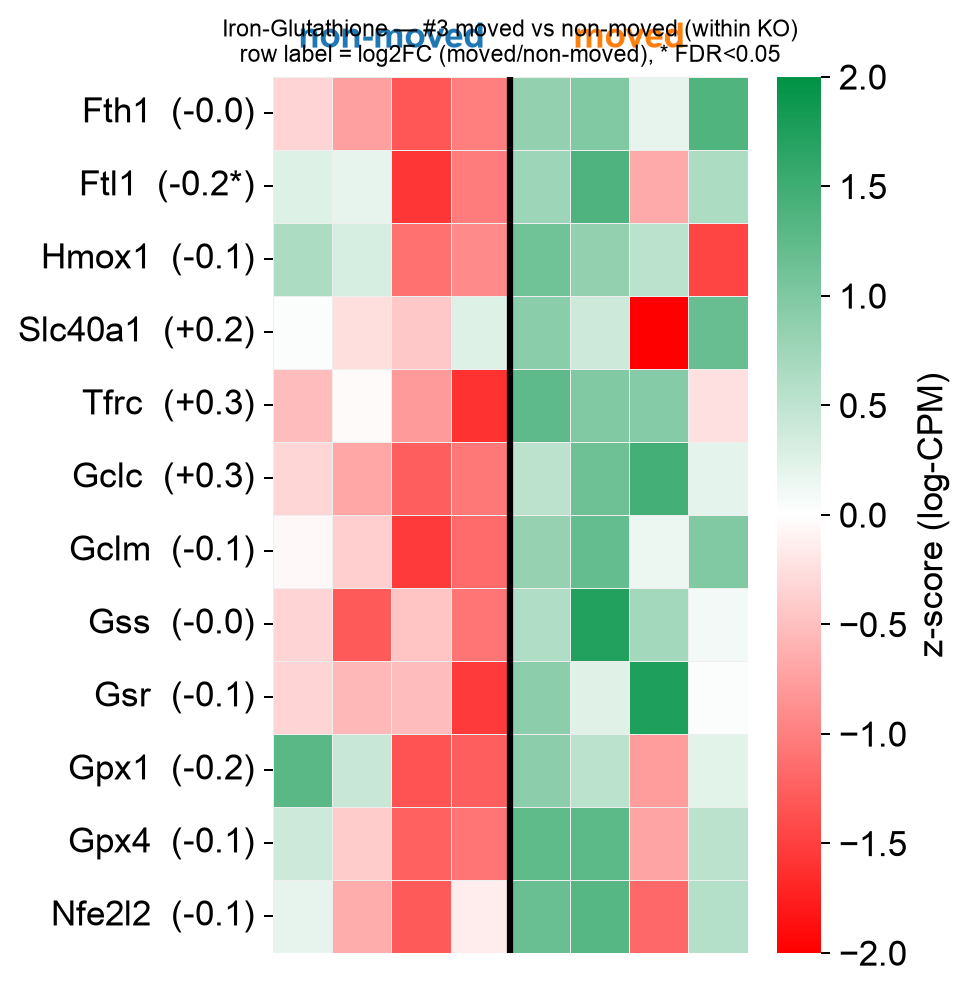

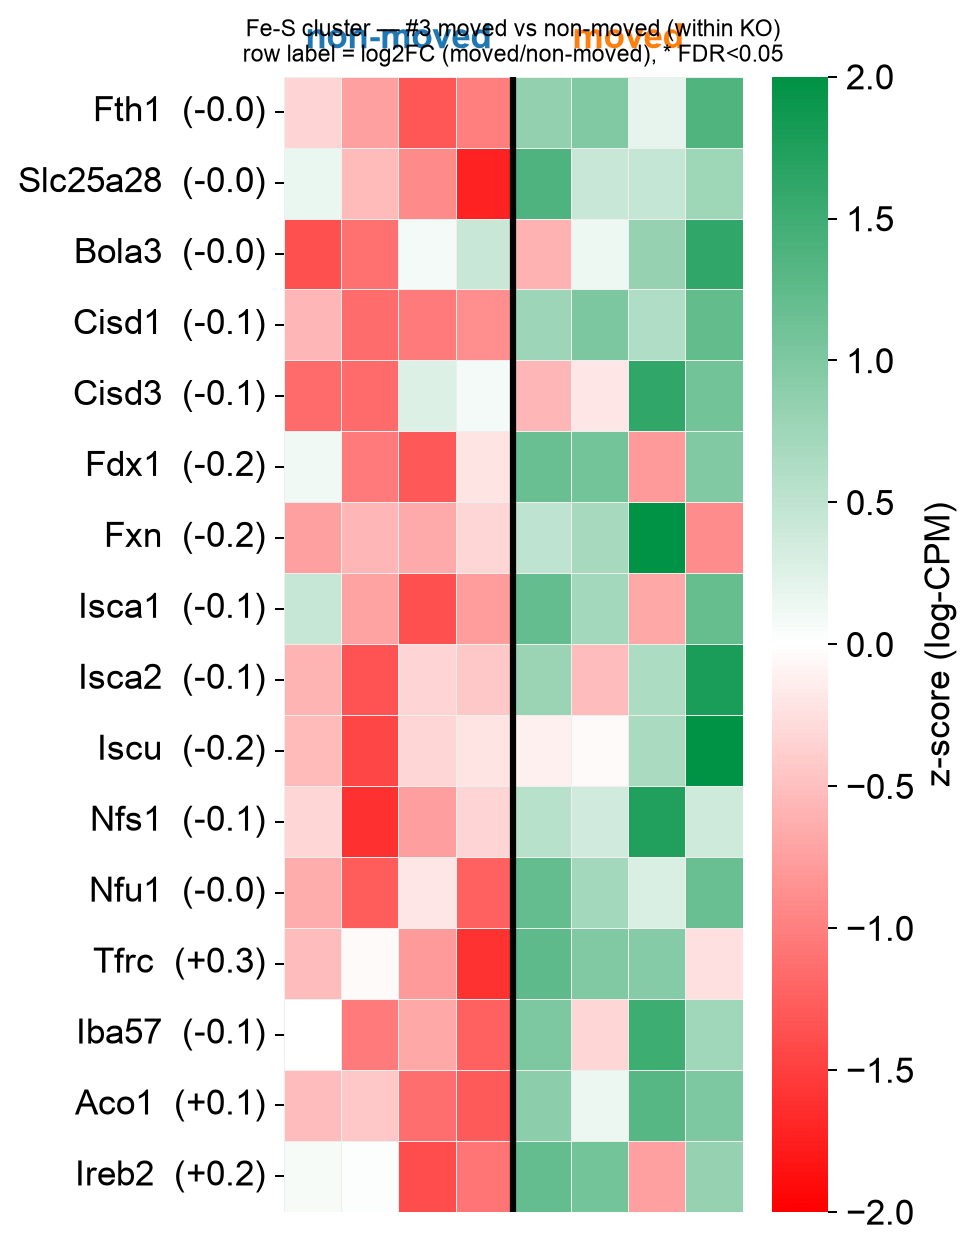

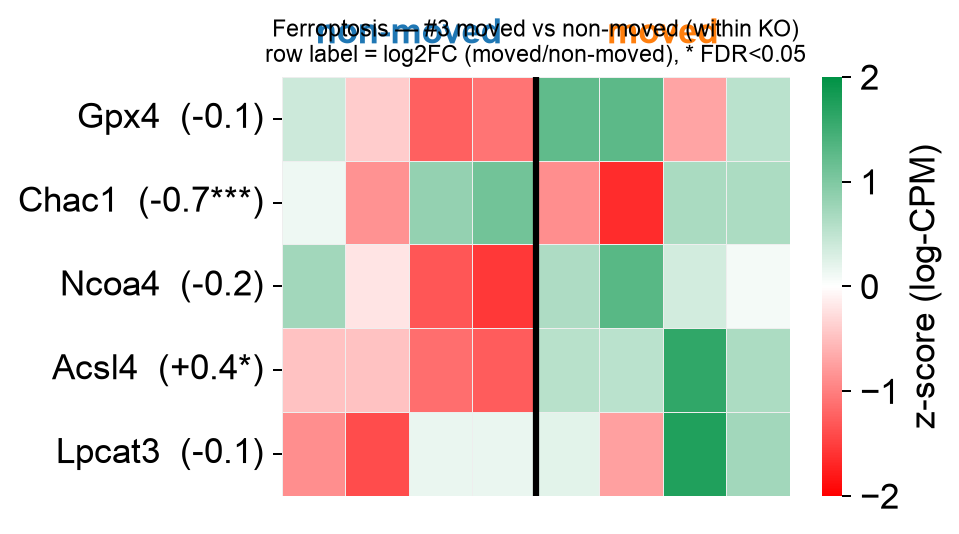

In [31]:
import numpy as np, pandas as pd, scanpy as sc, decoupler as dc
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

STATE_LABELS = {"0":"Mature β","1":"Mature β","4":"Mature β","5":"Mature β","6":"Immature β",
    "2":"Dedifferentiated β","9":"Dedifferentiated β","3":"Transitional β","7":"Transitional β","na":"Bihormonal β"}
MOVED = {"Dedifferentiated β","Bihormonal β"}; NONMOVED = {"Mature β"}; ALIAS = {"Ngn3":"Neurog3"}
GENE_GROUPS = {
 "Beta identity": ["Ins1","Ins2","Mafa","Nkx6-1","Pdx1","Ucn3","Slc2a2","Iapp","Gck","Neurod1","Chga","Pcsk1","Ngn3"],
 "Dedifferentiation": ["Aldh1a3","Gcg","Chgb","Mafb","Sox9","Rbp4","Ptf1a","Hnf1b"],
 "OXPHOS": ["Nfu1","Lias","Sdhb","Ndufs1","Uqcrc2","Cox5a","Atp5f1b"],
 "Stress": ["Atf4","Ddit3","Trib3","Hspa5","Hspd1","Hspe1","Atf5","Clpp","Lonp1"],
 "Iron-Glutathione": ["Fth1","Ftl1","Hmox1","Slc40a1","Tfrc","Gclc","Gclm","Gss","Gsr","Gpx1","Gpx4","Nfe2l2"],
 "Fe-S cluster": ["Fth1","Slc25a28","Bola3","Cisd1","Cisd3","Fdx1","Fdx2","Fxn","Isca1","Isca2","Iscu","Nfs1","Nfu1","Tfrc","Iba57","Aco1","Ireb2"],
 "Ferroptosis": ["Gpx4","Chac1","Ncoa4","Acsl4","Lpcat3"]}

# rebuild the #3 pseudobulk (KO beta, moved vs non-moved, per animal), log-CPM
ko = adata[(adata.obs.cell_type.isin(["beta","beta_bihormonal"])) & (adata.obs.genotype=="KO")].copy()
ko = ko[~ko.obs["beta_cluster"].astype(str).isin(["8","10"])].copy()
_s = ko.obs["beta_cluster"].astype(str).map(lambda c: STATE_LABELS.get(c,c))
ko.obs["status"] = np.where(_s.isin(MOVED),"moved", np.where(_s.isin(NONMOVED),"nonmoved", None))
ko = ko[ko.obs["status"].notna()].copy()
ko.obs["pb"] = ko.obs["sample_id"].astype(str) + "__" + ko.obs["status"]
pb = dc.pp.pseudobulk(ko, sample_col="pb", groups_col=None, mode="sum", layer="counts")
m = ko.obs.drop_duplicates("pb").set_index("pb")
pb.obs["status"] = pb.obs.index.map(m["status"]); pb.obs["mouse_id"] = pb.obs.index.map(m["mouse_id"])
ncol = "psbulk_cells" if "psbulk_cells" in pb.obs else "psbulk_n_cells"
pb = pb[(pb.obs[ncol]>=10) & (pb.obs["psbulk_counts"]>=1000)].copy()
sc.pp.normalize_total(pb, target_sum=1e6); sc.pp.log1p(pb)
pb.obs["ord"] = pb.obs["status"].map({"nonmoved":0,"moved":1})
cols = pb.obs.sort_values(["ord","mouse_id"]).index.tolist()
n_nm = int((pb.obs.loc[cols,"status"]=="nonmoved").sum())

r3 = res3.set_index("gene")
def stars(p): return "" if pd.isna(p) else ("***" if p<.001 else "**" if p<.01 else "*" if p<.05 else "")
gwr = LinearSegmentedColormap.from_list("rwg", ["#ff0000","#ffffff","#009245"])

for cat, gl in GENE_GROUPS.items():
    genes = [ALIAS.get(g,g) for g in gl if ALIAS.get(g,g) in pb.var_names]
    if not genes: continue
    X = pd.DataFrame(np.asarray(pb[cols, genes].X), index=cols, columns=genes).T
    z = X.sub(X.mean(1), axis=0).div(X.std(1).replace(0, np.nan), axis=0)
    ylab = [f"{g}  ({r3.loc[g,'log2FoldChange']:+.1f}{stars(r3.loc[g,'padj'])})" if g in r3.index else g for g in genes]
    fig, ax = plt.subplots(figsize=(5.5, 0.36*len(genes)+1.4))
    sns.heatmap(z, cmap=gwr, center=0, vmin=-2, vmax=2, yticklabels=ylab, xticklabels=False,
                linewidths=0.4, linecolor="#eee", cbar_kws={"label":"z-score (log-CPM)"}, ax=ax)
    ax.axvline(n_nm, color="k", lw=2.5)
    ax.text(n_nm/2, -0.4, "non-moved", ha="center", color="#1f77b4", fontweight="bold")
    ax.text(n_nm+(len(cols)-n_nm)/2, -0.4, "moved", ha="center", color="#ff7f0e", fontweight="bold")
    ax.set_title(f"{cat} — #3 moved vs non-moved (within KO)\nrow label = log2FC (moved/non-moved), * FDR<0.05", fontsize=9)
    ax.grid(False)
    fig.tight_layout(); fig.savefig(cfg.FIG_DIR/f"05_h3_{cat.replace(' ','_').replace('/','_')}.png", dpi=300, bbox_inches="tight")
    plt.show()

/var/folders/v8/0kqbc05x4293xgqwf03bq__80000gn/T/ipykernel_9794/142735607.py:43: UserWarning: Glyph 8599 (\N{NORTH EAST ARROW}) missing from font(s) Arial.
  sns.despine(); fig.tight_layout()
/var/folders/v8/0kqbc05x4293xgqwf03bq__80000gn/T/ipykernel_9794/142735607.py:43: UserWarning: Glyph 9670 (\N{BLACK DIAMOND}) missing from font(s) Arial.
  sns.despine(); fig.tight_layout()
/var/folders/v8/0kqbc05x4293xgqwf03bq__80000gn/T/ipykernel_9794/142735607.py:44: UserWarning: Glyph 8599 (\N{NORTH EAST ARROW}) missing from font(s) Arial.
  fig.savefig(cfg.FIG_DIR / "05b_pathway_partition.png", dpi=300, bbox_inches="tight")
/var/folders/v8/0kqbc05x4293xgqwf03bq__80000gn/T/ipykernel_9794/142735607.py:44: UserWarning: Glyph 9670 (\N{BLACK DIAMOND}) missing from font(s) Arial.
  fig.savefig(cfg.FIG_DIR / "05b_pathway_partition.png", dpi=300, bbox_inches="tight")
/Users/sashe/miniconda3/envs/bola3-islets/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8599 (\N{NORTH

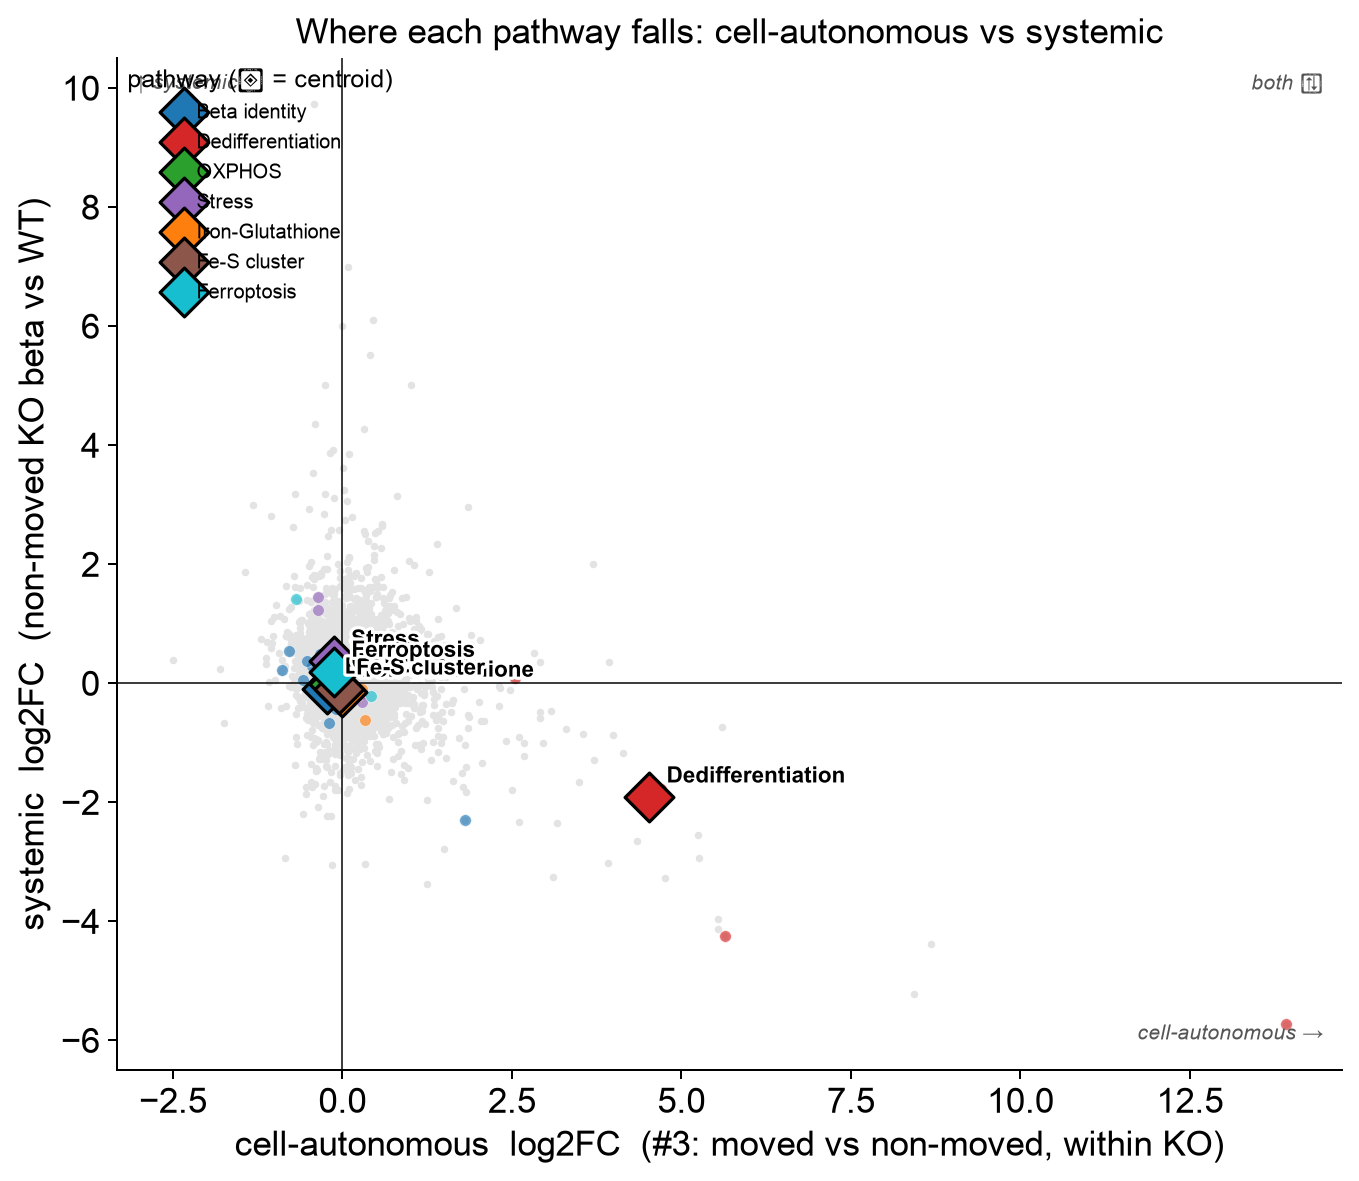

In [39]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import matplotlib.patheffects as pe

GENE_GROUPS = {
 "Beta identity": ["Ins1","Ins2","Mafa","Nkx6-1","Pdx1","Ucn3","Slc2a2","Iapp","Gck","Neurod1","Chga","Pcsk1","Ngn3"],
 "Dedifferentiation": ["Aldh1a3","Gcg","Chgb","Mafb","Sox9","Rbp4","Ptf1a","Hnf1b"],
 "OXPHOS": ["Nfu1","Lias","Sdhb","Ndufs1","Uqcrc2","Cox5a","Atp5f1b"],
 "Stress": ["Atf4","Ddit3","Trib3","Hspa5","Hspd1","Hspe1","Atf5","Clpp","Lonp1"],
 "Iron-Glutathione": ["Fth1","Ftl1","Hmox1","Slc40a1","Tfrc","Gclc","Gclm","Gss","Gsr","Gpx1","Gpx4","Nfe2l2"],
 "Fe-S cluster": ["Slc25a28","Bola3","Cisd1","Fxn","Isca1","Isca2","Iscu","Nfs1","Aco1","Ireb2"],
 "Ferroptosis": ["Gpx4","Chac1","Ncoa4","Acsl4","Lpcat3"],
}
ALIAS = {"Ngn3":"Neurog3"}
cat_col = {"Beta identity":"#1f77b4","Dedifferentiation":"#d62728","OXPHOS":"#2ca02c",
           "Stress":"#9467bd","Iron-Glutathione":"#ff7f0e","Fe-S cluster":"#8c564b","Ferroptosis":"#17becf"}

fig, ax = plt.subplots(figsize=(7.8, 6.8))
ax.scatter(m.lfc_auto, m.lfc_syst, s=4, c="#e3e3e3", rasterized=True)          # all genes, grey
ax.axhline(0, c="k", lw=.6); ax.axvline(0, c="k", lw=.6)

for cat, genes in GENE_GROUPS.items():
    gs = [ALIAS.get(g, g) for g in genes if ALIAS.get(g, g) in m.index]
    if not gs: continue
    sub = m.loc[gs]
    ax.scatter(sub.lfc_auto, sub.lfc_syst, s=22, c=cat_col[cat], alpha=0.65,
               edgecolor="white", linewidth=0.3)
    cx, cy = sub.lfc_auto.mean(), sub.lfc_syst.mean()
    ax.scatter(cx, cy, s=190, c=cat_col[cat], marker="D", edgecolor="k", linewidth=1.3, zorder=6, label=cat)
    ax.annotate(cat, (cx, cy), fontsize=9, fontweight="bold", xytext=(7, 6),
                textcoords="offset points", zorder=7,
                path_effects=[pe.withStroke(linewidth=2.6, foreground="white")])

# region definitions (in words, not shading — class is by significance)
ax.text(0.985, 0.03, "cell-autonomous →", transform=ax.transAxes, ha="right", fontsize=8.5, style="italic", color="#555")
ax.text(0.015, 0.985, "↑ systemic", transform=ax.transAxes, va="top", fontsize=8.5, style="italic", color="#555")
ax.text(0.985, 0.985, "both ↗", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, style="italic", color="#555")

ax.set_xlabel("cell-autonomous  log2FC  (#3: moved vs non-moved, within KO)")
ax.set_ylabel("systemic  log2FC  (non-moved KO beta vs WT)")
ax.set_title("Where each pathway falls: cell-autonomous vs systemic")
ax.legend(frameon=False, fontsize=8, loc="upper left", title="pathway (◆ = centroid)")
ax.grid(False)
sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "05b_pathway_partition.png", dpi=300, bbox_inches="tight")
plt.show()

The partition scatter — every beta gene placed by its cell-autonomous effect (x, from #3) vs its systemic effect (y, from non-moved-KO-vs-WT, the clean beta analog of 05b's contrast C):

cell-autonomous (red): significant in #3 only → requires the dedifferentiation transition itself. These are your strongest claims.
systemic (blue): significant only in non-moved KO beta → driven by the animals' KO environment (glucose intolerance), present even in beta cells that didn't dedifferentiate.
both (purple): the lesion and the environment push together — common for stress genes.
Watch where Esr1/Chac1/Ddit3 land (expect systemic or both) vs Aldh1a3/Gcg/Pyy/secretion genes (expect cell-autonomous).

The secretion-coupling test — your in vitro GSIS defect predicts these genes fall cell-autonomously. Red bars (down, FDR<0.05) confirm the prediction; the table gives the numbers. This is a direct, figure-ready test of a specific physiological phenotype.


Thought process
Thought process
Both are strong, figure-ready results. Let me read them, then we open 06.

The partition (cell-autonomous vs systemic)
The counts tell the core story: systemic 3,016 · cell-autonomous 751 · both 391 · neither 7,698. So the systemic component (the animals' glucose intolerance) dominates the beta transcriptome — but there's a solid, real cell-autonomous set (751 + 391). And the genes land where they should:

Cell-autonomous (red, high x / low y): Aldh1a3 — the dedifferentiation marker, driven by the state transition itself, not the systemic milieu.
Systemic (blue, high y): Chac1 (and the ISR/stress axis) — present even in non-moved KO beta.
Both, bottom-right: Gcg, Pyy, Rbp4 — strongly cell-autonomous up (the dedifferentiation program) with a systemic down component. The dedifferentiation is cell-intrinsic.
This is exactly the separation you want to show: the dedifferentiation program is cell-autonomous; the stress program is largely systemic.

The insulin-secretion-coupling test — this is the one that ties to your in vitro GSIS defect
Your prediction was "secretion coupling falls cell-autonomously." The honest read: the glucose-sensing / metabolic arm falls, exactly as predicted —

Slc2a2 (GLUT2) — the biggest cell-autonomous decrease (red). This is the mouse beta-cell glucose sensor; losing it directly breaks GSIS. Mechanistically this is your headline.
Ucn3 down (maturity/functional identity), Mdh1 down (anaplerosis), Rab3a down (exocytosis).
But it's not uniform, and you should report it as such: the distal machinery goes up — Abcc8, Cacna1c, Cacna1d (K-ATP and Ca²⁺ channels). So it's not "all secretion genes fall." The cleanest interpretation: the cell-autonomous defect is concentrated in the proximal glucose-sensing/metabolism arm (Slc2a2, Ucn3, Mdh1) — which is precisely the step that translates glucose into an ATP signal, and precisely what fails in your in vitro GSIS assay. The distal channel up-regulation is likely compensatory or part of the dedifferentiated identity — a nuance, not a contradiction.

Effect sizes are small (log2FC −0.5 to +0.6) because #3 is a within-KO state contrast, but the directions are clean and mechanistically coherent: GLUT2 down cell-autonomously is a strong, specific link to your physiology.


### What to carry into notebook 06

- `05_pseudobulk_de_all.csv` — the full result table, which notebook 06 reads.
  Keep the **full** table, not just the significant rows: GSEA needs the
  complete ranking, and throwing away the non-significant genes throws away the
  information that makes the enrichment test work.
- Whether Bola3 itself validated. Everything downstream is contingent on it.
- Which cell type to focus the pathway analysis on.